## Introducción

He preparado este notebook como material complementario a las clases, con el objetivo de ayudaros a comprender mejor los conceptos de computación cuántica y su implementación práctica mediante Python y Qiskit.

He incluido explicaciones teóricas, ejemplos de código, circuitos cuánticos y diferentes herramientas de visualización para que podáis experimentar, reforzar los conocimientos adquiridos y profundizar de forma autónoma en aquellos conceptos que os resulten más interesantes.

Algunos de los contenidos de este notebook amplían lo visto en clase. Quiero aclararos que, **de cara al examen, como os he comentado en nuestra última clase, únicamente os pediré los contenidos que hayamos trabajado durante las clases y las prácticas de la asignatura.** Por tanto, no es necesario que estudiéis todos los contenidos adicionales que he incluido.

Os animo a utilizar este material como herramienta de aprendizaje, a modificar los circuitos, experimentar con distintas puertas cuánticas, analizar los resultados y, sobre todo, intentar comprender por qué se producen.

Mi objetivo no es que memoricéis código, sino que comprendáis los fundamentos de la computación cuántica y seáis capaces de trasladar estos conceptos a un entorno de programación real.

# Computación cuántica con Python y Qiskit
**Nebrija · Cuaderno de prácticas**

De IBM Quantum Composer a Python. Ejecuta las celdas en orden. Los apartados locales no requieren cuenta IBM. Los resultados esperados se indican junto a cada ejercicio.

**Versión 1.3 — edición comentada en español.** Lee cada explicación antes de ejecutar el código; predice el resultado, ejecútalo y compara. Las palabras reservadas de Python y los nombres de la API se mantienen en inglés.

## 0. Instalación
Ejecutar solo si faltan dependencias y reiniciar el kernel si es necesario.

#### Preparación del entorno

**Qué vamos a hacer y por qué.** Las importaciones permiten utilizar clases de Qiskit sin escribir su ruta completa. NumPy opera con números complejos y matrices; Matplotlib genera gráficos; Aer simula circuitos. SHOTS indica cuántas veces repetimos la ejecución. Las funciones auxiliares se reutilizan durante todo el cuaderno.

**Qué debes observar al ejecutar la celda.** Ejecuta esta celda primero. Si aparece ModuleNotFoundError, instala las dependencias y reinicia el kernel. Una semilla fija facilita reproducir el muestreo, pero no convierte las frecuencias en probabilidades exactas.

In [4]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
# Descomenta si necesitas instalar las librerías:
# %pip install qiskit qiskit-aer qiskit-ibm-runtime matplotlib pylatexenc jupyter
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.quantum_info import Statevector, Operator, partial_trace, state_fidelity
from qiskit.visualization import plot_bloch_multivector, plot_state_qsphere, plot_histogram, plot_distribution, plot_state_city
from qiskit_aer import AerSimulator
from qiskit.primitives import StatevectorSampler
import qiskit
print(qiskit.__version__)
SHOTS = 1024
sim = AerSimulator()

2.2.3


## 0.1. Distintas formas de construir circuitos
El mismo estado de Bell se puede preparar mediante índices, registros explícitos, instrucciones de la biblioteca o una función reutilizable. `circuit` y `qc` son nombres de variables, no propiedades especiales de QuantumCircuit.

#### Construcción de un circuito

**Qué vamos a hacer y por qué.** QuantumCircuit reserva cables, inicialmente en cero. Los índices comienzan en 0. H crea una superposición en q0 y CX invierte q1 condicionada a q0. Los registros permiten nombrar y agrupar cables; append incorpora objetos de tipo puerta. Las funciones permiten reutilizar un patrón sin copiar código.

**Qué debes observar al ejecutar la celda.** Compara los diagramas: aunque la sintaxis sea diferente, las operaciones cuánticas son equivalentes. Los bits clásicos solo almacenan resultados cuando se mide.

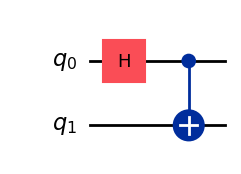

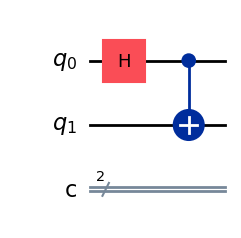

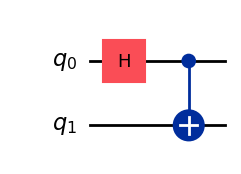

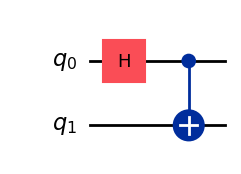

In [7]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
from qiskit.circuit.library import HGate, CXGate
from qiskit.circuit import Parameter
from qiskit.visualization import circuit_drawer, plot_state_city, plot_state_hinton

circuit = QuantumCircuit(2, name="Bell")
circuit.h(0)
circuit.cx(0, 1)

qr_demo = QuantumRegister(2, 'q')
cr_demo = ClassicalRegister(2, 'c')
registrado = QuantumCircuit(qr_demo, cr_demo)
registrado.h(qr_demo[0])
registrado.cx(qr_demo[0], qr_demo[1])

por_puertas = QuantumCircuit(2)
por_puertas.append(HGate(), [0])
por_puertas.append(CXGate(), [0, 1])

def crear_bell():
    qc = QuantumCircuit(2)
    qc.h(0)
    qc.cx(0, 1)
    return qc

for ejemplo in [circuit, registrado, por_puertas, crear_bell()]:
    display(ejemplo.draw('mpl'))
    assert Statevector.from_instruction(ejemplo).equiv(Statevector.from_instruction(circuit))

### Circuitos parametrizados y preparación directa de estados
Un parámetro simbólico se puede reutilizar con diferentes valores. `initialize` prepara un estado normalizado, pero incluye reset y no representa en general una operación unitaria reversible.

#### Parámetros y amplitudes

**Qué vamos a hacer y por qué.** Parameter define un símbolo que todavía no tiene valor numérico. assign_parameters crea un circuito con un ángulo concreto. RY gira alrededor del eje Y de Bloch; con π/2 desde cero prepara |+⟩. initialize recibe amplitudes complejas normalizadas.

**Qué debes observar al ejecutar la celda.** El segundo ejemplo debe mostrar amplitudes 1/√2 y i/√2, con probabilidades iguales y fase relativa π/2. No confundas un parámetro simbólico con una variable clásica medida.

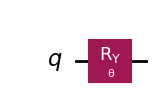

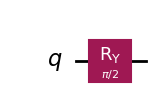

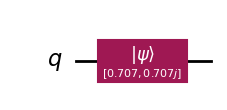

[0.70710678+0.j         0.        +0.70710678j]


In [10]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
theta_demo = Parameter('θ')
parametrico = QuantumCircuit(1)
parametrico.ry(theta_demo, 0)
display(parametrico.draw('mpl'))
con_valor = parametrico.assign_parameters({theta_demo: np.pi/2})
display(con_valor.draw('mpl'))
preparado = QuantumCircuit(1)
preparado.initialize([1/np.sqrt(2), 1j/np.sqrt(2)], 0)
display(preparado.draw('mpl'))
print(Statevector.from_instruction(preparado).data)

## 0.2. Inspección de circuitos: objeto `circuit` y propiedad `.data`
`QuantumCircuit.data` contiene las instrucciones en orden; cada `CircuitInstruction` expone `operation`, `qubits` y `clbits`. `Statevector.data` contiene amplitudes complejas; `Operator.data` contiene una matriz. No existe una propiedad universal `QuantumCircuit.circuit`. Una instrucción compuesta puede exponer su circuito interno mediante `.definition`.

#### Leer el circuito como estructura de datos

**Qué vamos a hacer y por qué.** Cada elemento de data es una instrucción con una operación y los cables sobre los que actúa. find_bit recupera su índice en el circuito. params contiene ángulos u otros parámetros. depth cuenta capas de operaciones, mientras size cuenta operaciones (normalmente sin directivas como barreras).

**Qué debes observar al ejecutar la celda.** Localiza H y CX, sus índices y los registros. Operator.data representa una matriz unitaria, no las amplitudes de un estado. Para circuitos con medidas no se puede obtener directamente un operador unitario.

In [13]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
print(circuit)
print(circuit.data)
print('Primera instrucción:', circuit.data[0])
for instruccion in circuit.data:
    print(instruccion.operation.name,
          [circuit.find_bit(q).index for q in instruccion.qubits],
          [circuit.find_bit(b).index for b in instruccion.clbits],
          instruccion.operation.params)
print('Qubits:', circuit.num_qubits, 'bits clásicos:', circuit.num_clbits)
print('Registros:', circuit.qregs, circuit.cregs)
print('Profundidad:', circuit.depth(), 'operaciones:', circuit.count_ops())
print('Tamaño:', circuit.size(), 'fase global:', circuit.global_phase)
print('Amplitudes:', Statevector.from_instruction(circuit).data)
print('Matriz:', Operator(circuit).data)
# Un circuito con mediciones sí muestra los bits clásicos en data.
medido_demo = circuit.copy()
medido_demo.measure_all()
for instruccion in medido_demo.data:
    print(instruccion.operation.name, instruccion.qubits, instruccion.clbits)

     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘
[CircuitInstruction(operation=Instruction(name='h', num_qubits=1, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=0>,), clbits=()), CircuitInstruction(operation=Instruction(name='cx', num_qubits=2, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=0>, <Qubit register=(2, "q"), index=1>), clbits=())]
Primera instrucción: CircuitInstruction(operation=Instruction(name='h', num_qubits=1, num_clbits=0, params=[]), qubits=(<Qubit register=(2, "q"), index=0>,), clbits=())
h [0] [] []
cx [0, 1] [] []
Qubits: 2 bits clásicos: 0
Registros: [QuantumRegister(2, 'q')] []
Profundidad: 2 operaciones: OrderedDict({'h': 1, 'cx': 1})
Tamaño: 2 fase global: 0.0
Amplitudes: [0.70710678+0.j 0.        +0.j 0.        +0.j 0.70710678+0.j]
Matriz: [[ 0.70710678+0.j  0.70710678+0.j  0.        +0.j  0.        +0.j]
 [ 0.        +0.j  0.        +0.j  0.70710678+0.j -0.70710678+0.j]
 [ 0.        +0.j  

## 0.3. Visualización de circuitos y estilos
`draw()` admite texto, Matplotlib y código fuente LaTeX. El renderizado LaTeX como imagen requiere herramientas externas, por eso no se ejecuta por defecto. Cambiar colores u orden visual no modifica el estado cuántico.

#### Representaciones gráficas

**Qué vamos a hacer y por qué.** text devuelve un esquema de caracteres; mpl produce una figura; latex_source devuelve código LaTeX. style permite modificar el fondo, scale el tamaño y reverse_bits el orden visual de los cables. plot_barriers y cregbundle afectan a la presentación.

**Qué debes observar al ejecutar la celda.** Cambiar el fondo o invertir el dibujo no modifica las operaciones ni el orden de bits de los resultados. Usa filename para guardar una figura si lo necesitas.

     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘


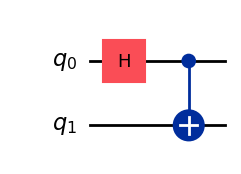

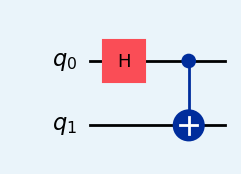

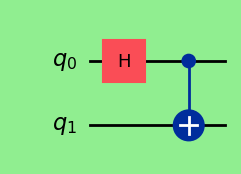

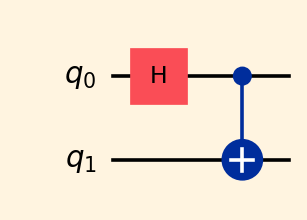

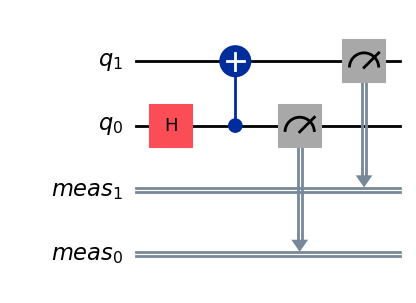

\documentclass[border=2px]{standalone}

\usepackage[braket, qm]{qcircuit}
\usepackage{graphicx}

\begin{document}
\scalebox{1.0}{
\Qcircuit @C=1.0em @R=0.2em @!R { \\
	 	\nghost{{q}_{0} :  } & \lstick{{q}_{0} :  } & \gate{\mathrm{H}} & \ctrl{1} & \qw & \qw\\
	 	\nghost{{q}_{1} :  } & \lstick{{q}_{1} :  } & \qw & \targ & \qw & \qw\\
\\ }}
\end{document}


In [16]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
print(circuit.draw(output='text'))
display(circuit.draw(output='mpl'))
display(circuit_drawer(circuit, output='mpl', style={'backgroundcolor':'#EAF4FA'}))
display(circuit.draw('mpl', style={'backgroundcolor':'lightgreen'}))
display(circuit.draw('mpl', style={'backgroundcolor':'#FFF4E0'}, scale=1.3))
display(medido_demo.draw('mpl', reverse_bits=True, plot_barriers=False, cregbundle=False))
print(circuit.draw('latex_source')[:500])
# Opcional: circuit.draw('latex') si tienes las dependencias externas.
# Opcional: circuit.draw('mpl', filename='bell.png')

## 0.4. Unión de circuitos: compose, append y tensor
- `compose`: inserta las operaciones en los mismos cables o en cables elegidos.
- `append`: añade una puerta o instrucción como bloque; `decompose` expande su definición.
- `tensor`: combina circuitos sobre qubits distintos; el operando derecho ocupa los índices inferiores en la convención de Qiskit.
- `inplace=True` modifica el circuito receptor; por defecto `compose` devuelve otro circuito.

#### Componer frente a encapsular

**Qué vamos a hacer y por qué.** compose concatena operaciones sobre cables comunes o mapeados explícitamente. append añade una instrucción como bloque; to_gate exige un circuito unitario sin bits clásicos. decompose despliega el bloque. tensor construye un producto sobre cables independientes; el argumento derecho ocupa los índices inferiores.

**Qué debes observar al ejecutar la celda.** Comprueba que H seguida de Z no es lo mismo que Z seguida de H. copy evita modificar el original; inplace=True sí lo modifica. Operator.equiv compara operadores salvo fase global.

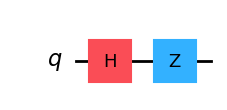

Original: OrderedDict({'h': 1}) combinado: OrderedDict({'h': 1, 'z': 1})


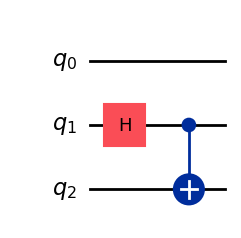

{'000': (0.7071067811865475+0j), '110': (0.7071067811865475+0j)}


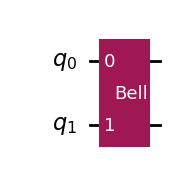

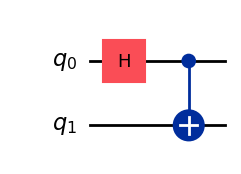

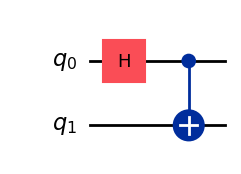

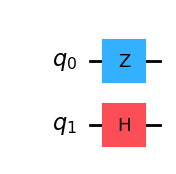

{'00': (0.7071067811865475+0j), '10': (0.7071067811865475+0j)}


In [19]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
a_demo = QuantumCircuit(1, name='H')
a_demo.h(0)
b_demo = QuantumCircuit(1, name='Z')
b_demo.z(0)
secuencial = a_demo.compose(b_demo)
display(secuencial.draw('mpl'))
print('Original:', a_demo.count_ops(), 'combinado:', secuencial.count_ops())
modificado = a_demo.copy()
modificado.compose(b_demo, inplace=True)
assert Operator(modificado).equiv(Operator(secuencial))

base_demo = QuantumCircuit(3)
base_demo.compose(circuit, qubits=[1,2], inplace=True)
display(base_demo.draw('mpl'))
print(Statevector.from_instruction(base_demo).to_dict())

bloque = QuantumCircuit(2)
bloque.append(circuit.to_gate(label='Bell'), [0,1])
display(bloque.draw('mpl'))
display(bloque.decompose().draw('mpl'))
display(bloque.data[0].operation.definition.draw('mpl'))
assert Operator(bloque).equiv(Operator(circuit))

paralelo = a_demo.tensor(b_demo)
display(paralelo.draw('mpl'))
print(Statevector.from_instruction(paralelo).to_dict())

## 0.5. Visualización del estado: amplitudes, fases y probabilidades
El vector de estado es una descripción del estado ideal antes de medir. QSphere representa el estado global; Bloch representa los estados reducidos individuales. Las barras de amplitud real e imaginaria no son probabilidades. Las matrices City y Hinton representan la matriz de densidad. En un dispositivo real no se obtiene directamente el statevector mediante una sola ejecución.

#### Interpretar las visualizaciones

**Qué vamos a hacer y por qué.** El statevector conserva módulo y fase de cada amplitud; los gráficos de parte real e imaginaria permiten identificar signos y números complejos. En QSphere el tamaño de los puntos indica probabilidad y el color codifica fase. Bloch representa las componentes X, Y y Z del estado reducido de cada qubit. City y Hinton muestran la matriz de densidad, incluidas coherencias.

**Qué debes observar al ejecutar la celda.** H, HS y HZ producen probabilidades 50/50, pero fases relativas 0, π/2 y π. Sus vectores de Bloch apuntan a +X, +Y y −X respectivamente. El histograma no distingue estas fases.

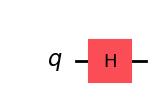

data: [0.70710678+0.j 0.70710678+0.j]


<IPython.core.display.Latex object>

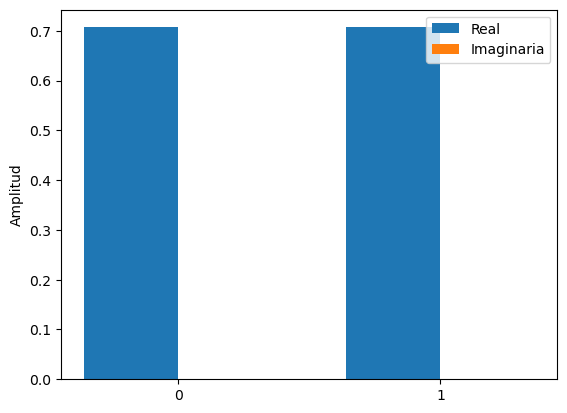

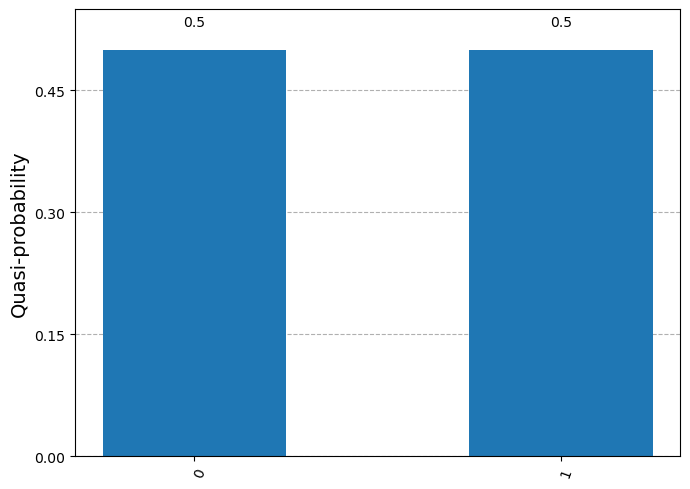

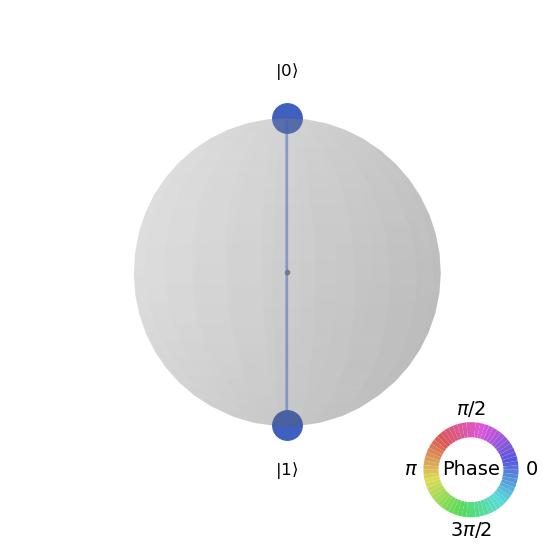

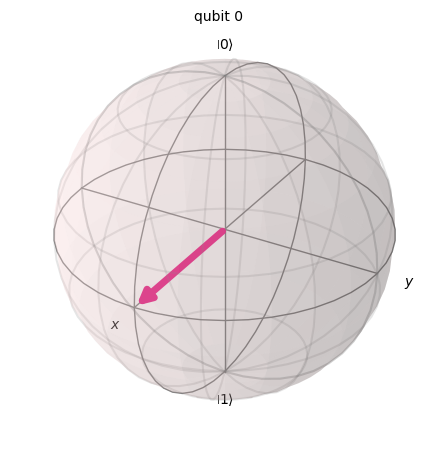

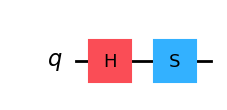

data: [0.70710678+0.j         0.        +0.70710678j]


<IPython.core.display.Latex object>

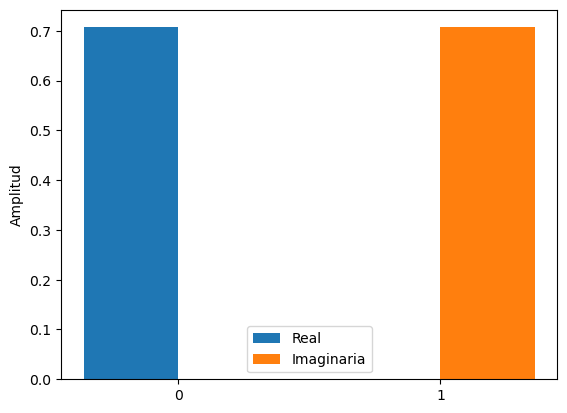

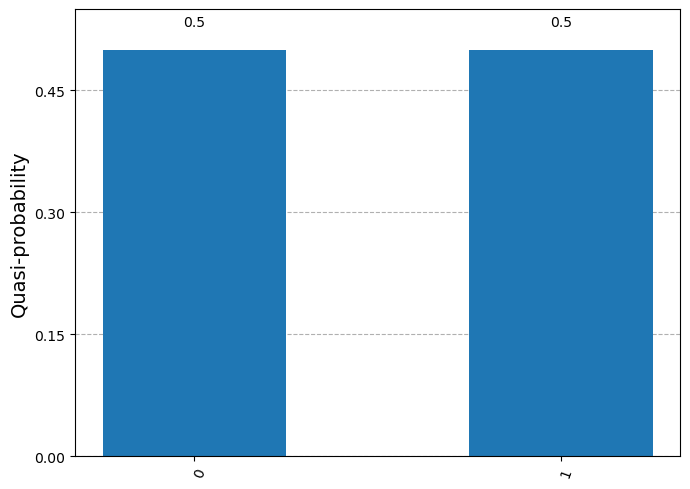

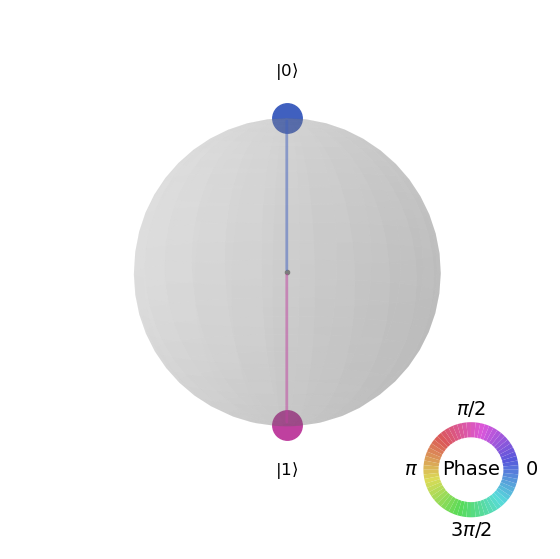

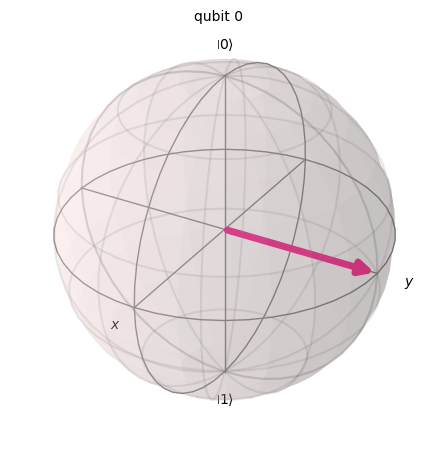

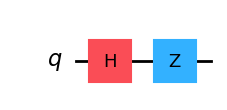

data: [ 0.70710678+0.j -0.70710678+0.j]


<IPython.core.display.Latex object>

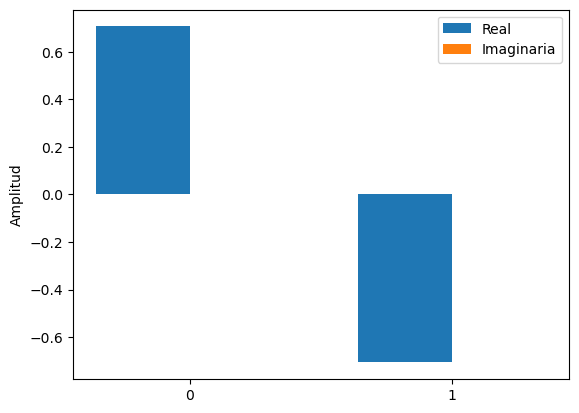

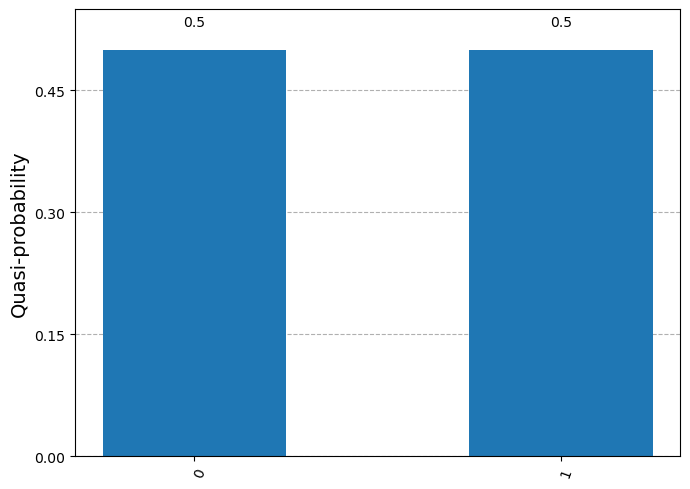

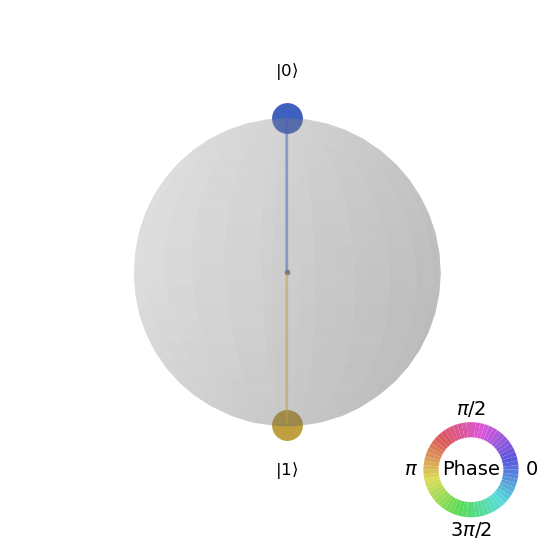

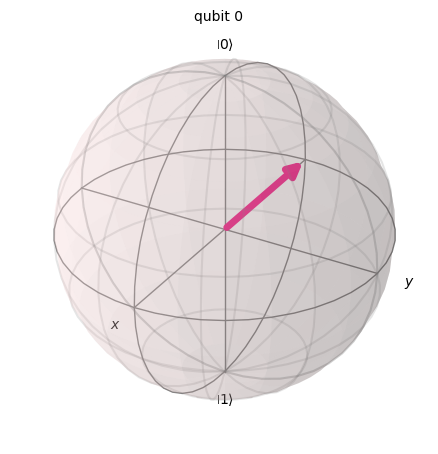

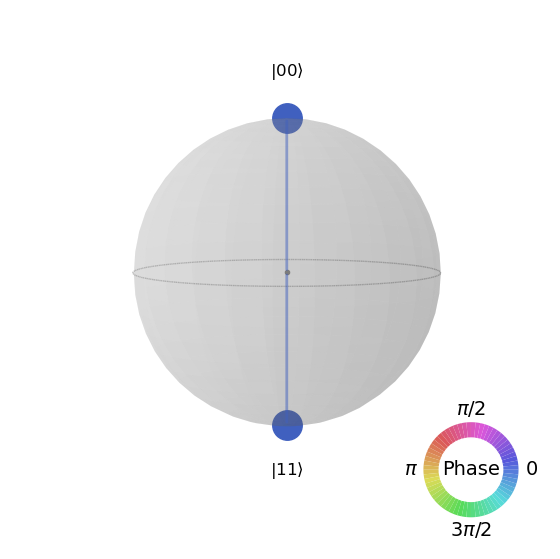

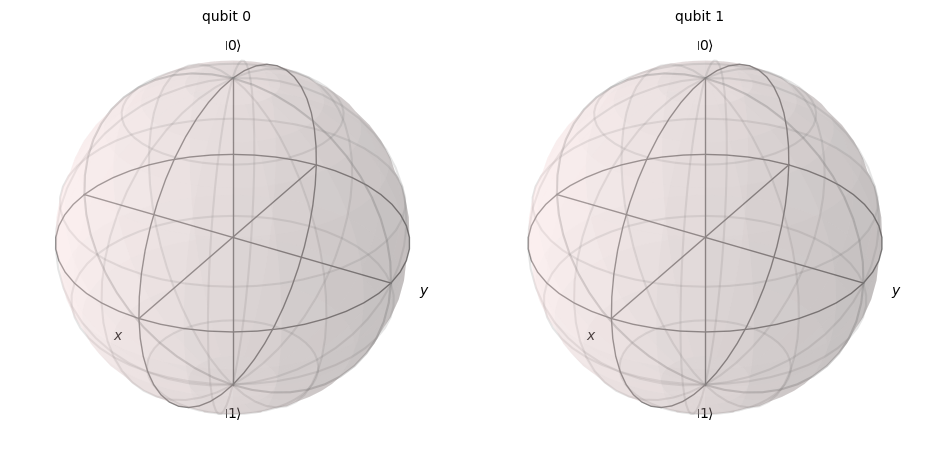

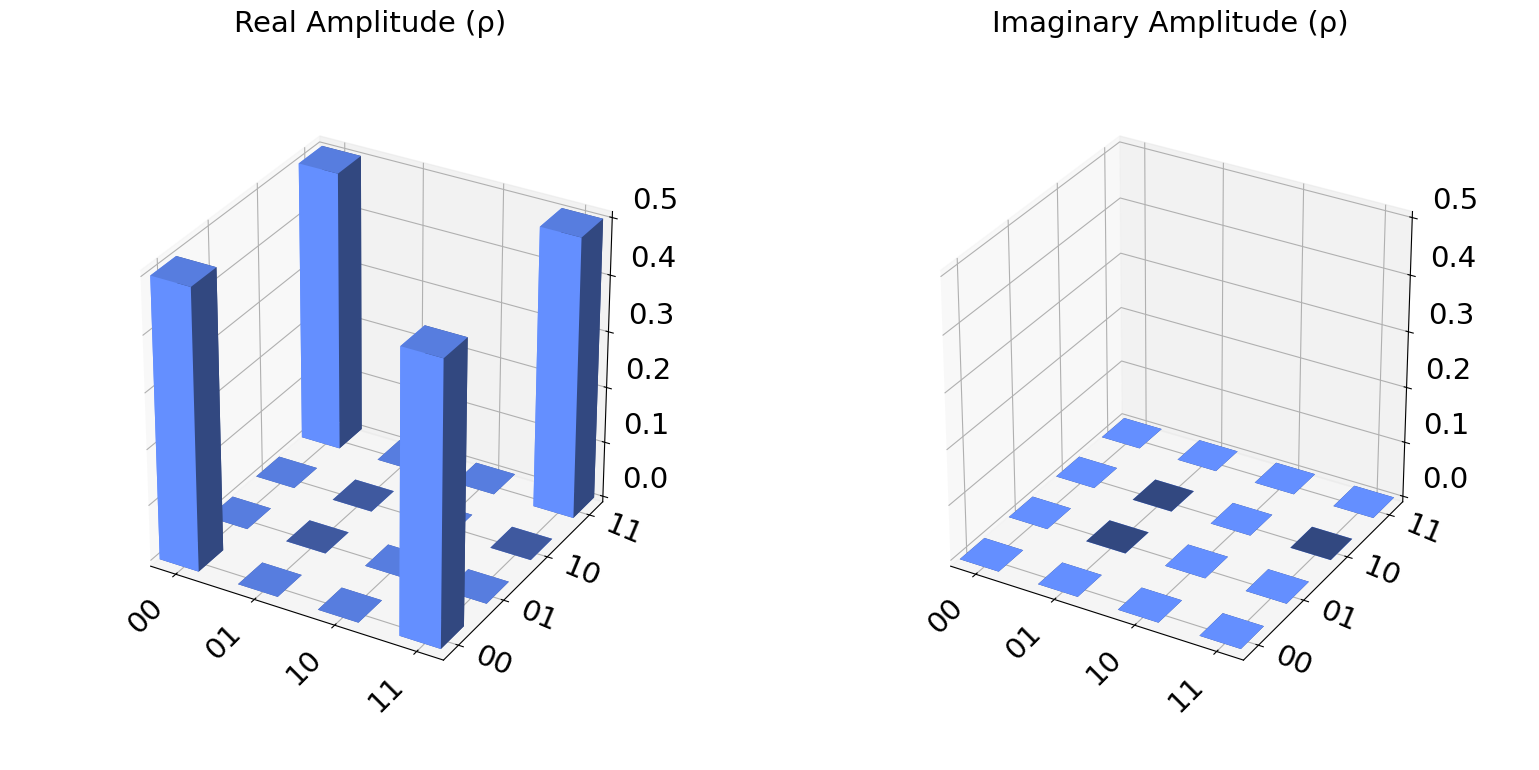

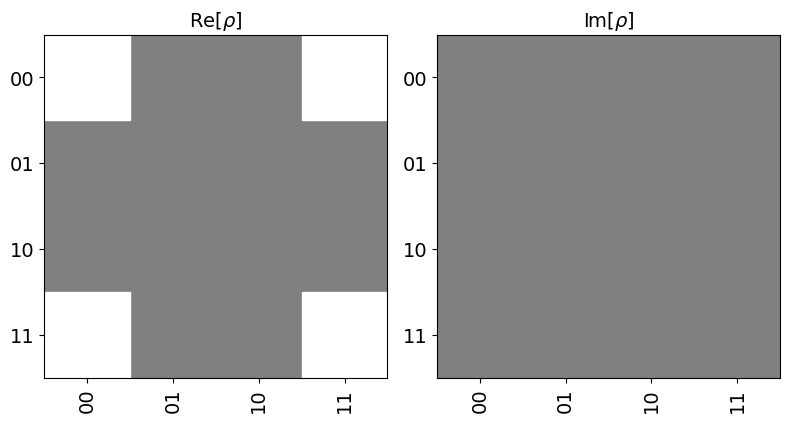

In [22]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
for puertas_demo in [('h',), ('h','s'), ('h','z')]:
    q_demo = QuantumCircuit(1)
    for g_demo in puertas_demo:
        getattr(q_demo,g_demo)(0)
    display(q_demo.draw('mpl'))
    estado_demo = Statevector.from_instruction(q_demo)
    print('data:', estado_demo.data)
    display(estado_demo.draw('latex'))
    etiquetas_demo = list(estado_demo.to_dict().keys())
    amplitudes_demo = list(estado_demo.to_dict().values())
    x_demo = np.arange(len(etiquetas_demo))
    fig, ax = plt.subplots()
    ax.bar(x_demo-0.18, np.real(amplitudes_demo), .36, label='Real')
    ax.bar(x_demo+0.18, np.imag(amplitudes_demo), .36, label='Imaginaria')
    ax.set_xticks(x_demo, etiquetas_demo); ax.set_ylabel('Amplitud'); ax.legend()
    plt.show(); plt.close(fig)
    display(plot_distribution(estado_demo.probabilities_dict()))
    display(plot_state_qsphere(estado_demo))
    display(plot_bloch_multivector(estado_demo))

estado_bell_demo = Statevector.from_instruction(circuit)
display(plot_state_qsphere(estado_bell_demo))
display(plot_bloch_multivector(estado_bell_demo))
display(plot_state_city(estado_bell_demo))
display(plot_state_hinton(estado_bell_demo))

### Ejercicios de construcción y visualización
1. Construye H–Z–H con métodos directos y con `compose`. Comprueba que equivale a X.
2. Crea un bloque Bell con `append`, descomponlo y cambia su fondo a azul claro.
3. Compara H, HS y HZ: ¿qué visualizaciones distinguen sus fases relativas si las probabilidades coinciden?
4. Inspecciona `.data` de un circuito antes y después de medir. Identifica las instrucciones y bits clásicos.
5. Une dos circuitos de un qubit con `tensor` y comprueba el orden de los cables.

## 1. Qubit y visualizaciones
$|\psi\rangle=\alpha|0\rangle+\beta|1\rangle$. Las probabilidades son $|\alpha|^2$ y $|\beta|^2$. Qiskit escribe los bits como $q_{n-1}\ldots q_0$. La fase de una amplitud nula no está definida.

#### Del vector de estado a la medición

**Qué vamos a hacer y por qué.** Para un qubit, α y β son números complejos y |α|²+|β|²=1. Para n qubits hay 2ⁿ amplitudes. Qiskit escribe q0 a la derecha en las cadenas binarias. La función analizar obtiene el estado ideal y muestra sus diferentes representaciones; medir usa repeticiones del circuito.

**Qué debes observar al ejecutar la celda.** Una amplitud negativa no implica probabilidad negativa. Una amplitud nula tiene fase indefinida. Compara las probabilidades exactas con las frecuencias observadas; estas fluctúan con el número de shots.

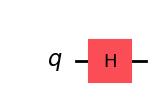

Statevector: [0.7071+0.j 0.7071+0.j]
0 amplitud= (0.7071+0j) probabilidad= 0.5 fase (rad)= 0.0
1 amplitud= (0.7071+0j) probabilidad= 0.5 fase (rad)= 0.0


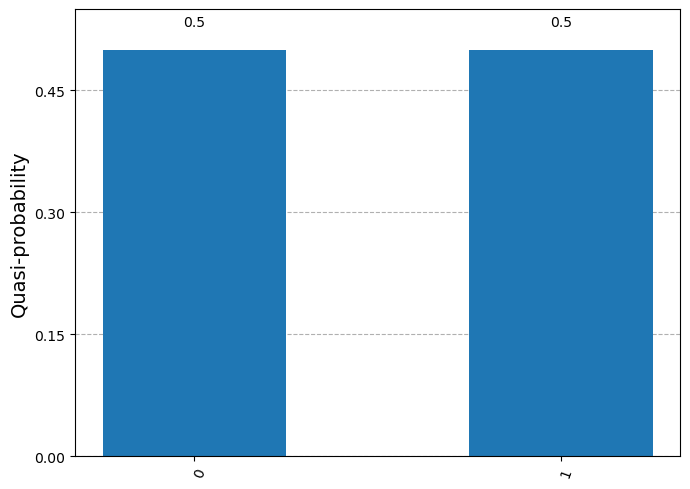

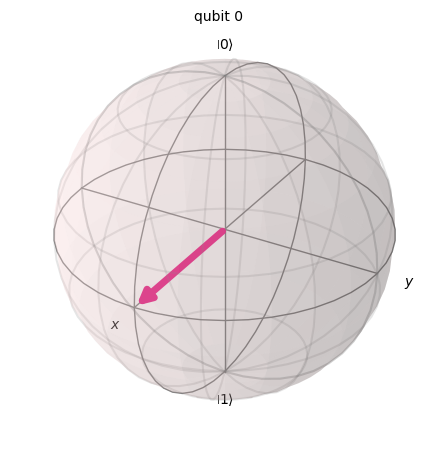

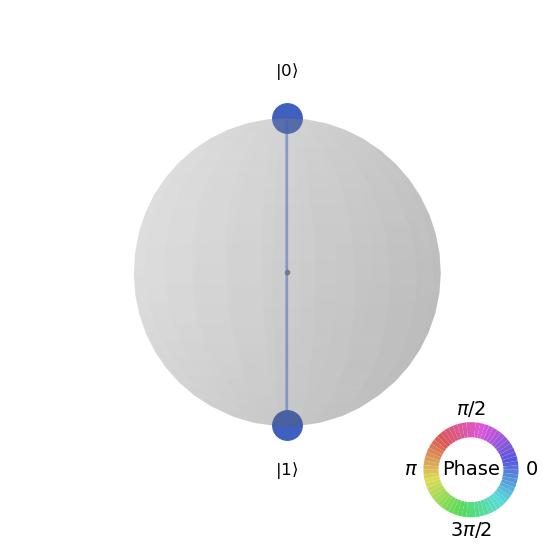

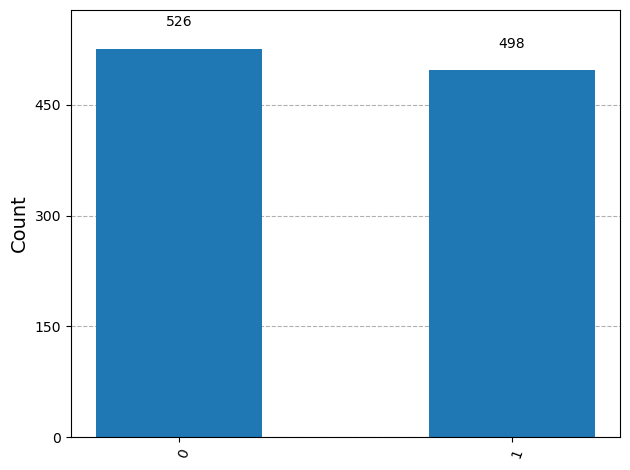

{'1': 498, '0': 526}

In [26]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
def analizar(qc):
    display(qc.draw('mpl'))
    sv = Statevector.from_instruction(qc)
    print('Statevector:', np.round(sv.data, 4))
    for k,a in sv.to_dict().items():
        print(k, 'amplitud=', np.round(a,4), 'probabilidad=', round(abs(a)**2,4),
              'fase (rad)=', round(np.angle(a),4) if abs(a)>1e-10 else 'indefinida')
    display(plot_distribution(sv.probabilities_dict()))
    display(plot_bloch_multivector(sv))
    display(plot_state_qsphere(sv))
    return sv

def medir(qc, shots=SHOTS, backend=sim):
    circuito = qc.copy()
    if circuito.num_clbits == 0:
        circuito.measure_all()
    counts = backend.run(transpile(circuito, backend), shots=shots, seed_simulator=42).result().get_counts()
    display(plot_histogram(counts))
    return counts

qc = QuantumCircuit(1)
qc.h(0)
sv = analizar(qc)
medir(qc)

## 2. Puertas y reversibilidad
Una puerta unitaria cumple $U^\dagger U=I$. La medición no es una puerta unitaria. Y sobre cero produce $i|1\rangle$. En Python `j` representa la unidad imaginaria.

#### Puertas como matrices

**Qué vamos a hacer y por qué.** I conserva el estado; X intercambia amplitudes; Y introduce además fases imaginarias; Z cambia el signo de |1⟩; H mezcla amplitudes; S y T añaden fases π/2 y π/4 a |1⟩. RX, RY y RZ realizan rotaciones parametrizadas. El producto U†U permite comprobar la unitariedad.

**Qué debes observar al ejecutar la celda.** Z, S y T sobre |0⟩ no producen cambios visibles; repite sobre |+⟩ para observar su efecto. Las rotaciones no conmutan en general y el orden de aplicación importa.

id 
 [[1.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]] unitaria: True
Estado: [1.+0.j 0.+0.j]
x 
 [[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]] unitaria: True
Estado: [0.+0.j 1.+0.j]
y 
 [[0.+0.j 0.-1.j]
 [0.+1.j 0.+0.j]] unitaria: True
Estado: [0.+0.j 0.+1.j]
z 
 [[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]] unitaria: True
Estado: [1.+0.j 0.+0.j]
h 
 [[ 0.707+0.j  0.707+0.j]
 [ 0.707+0.j -0.707+0.j]] unitaria: True
Estado: [0.707+0.j 0.707+0.j]
s 
 [[1.+0.j 0.+0.j]
 [0.+0.j 0.+1.j]] unitaria: True
Estado: [1.+0.j 0.+0.j]
t 
 [[1.   +0.j    0.   +0.j   ]
 [0.   +0.j    0.707+0.707j]] unitaria: True
Estado: [1.+0.j 0.+0.j]


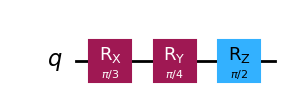

Statevector: [0.7011-0.4305j 0.561 -0.0923j]
0 amplitud= (0.7011-0.4305j) probabilidad= 0.6768 fase (rad)= -0.5507
1 amplitud= (0.561-0.0923j) probabilidad= 0.3232 fase (rad)= -0.1631


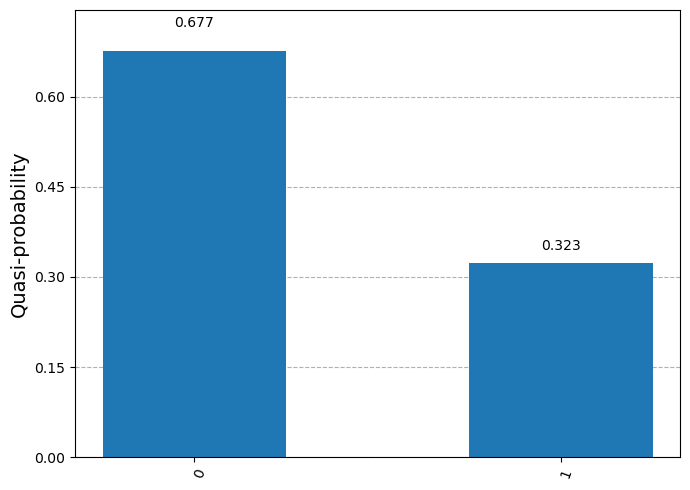

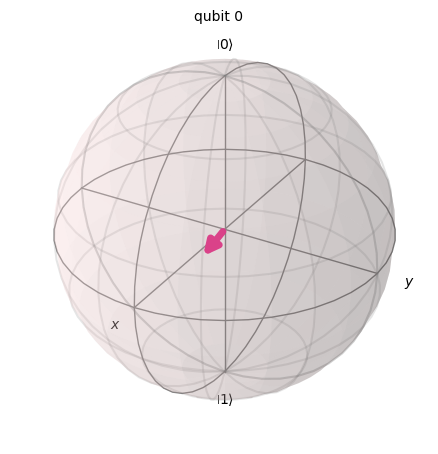

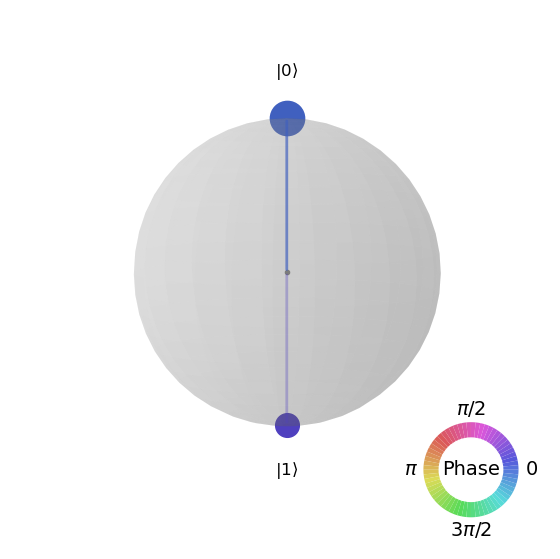

Statevector([0.70105738-0.43045933j, 0.56098553-0.09229596j],
            dims=(2,))


In [29]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
for gate in ['id','x','y','z','h','s','t']:
    q = QuantumCircuit(1)
    getattr(q, gate)(0)
    u = Operator(q).data
    print(gate, '\n', np.round(u,3), 'unitaria:', np.allclose(u.conj().T @ u,np.eye(2)))
    print('Estado:', np.round(Statevector.from_instruction(q).data,3))
q = QuantumCircuit(1)
q.rx(np.pi/3,0); q.ry(np.pi/4,0); q.rz(np.pi/2,0)
analizar(q)

## 3. Fase e interferencia
H prepara superposición; Z cambia la fase relativa; H convierte esa diferencia en probabilidades. HZH equivale a X. Una fase global no altera las probabilidades ni ningún observable.

#### Interferencia y fase

**Qué vamos a hacer y por qué.** H transforma |0⟩ en |+⟩ y |1⟩ en |−⟩. Una segunda H recombina amplitudes. Z entre ambas cambia el signo de una rama, haciendo que la interferencia favorezca |1⟩. Una fase global multiplica todas las amplitudes por el mismo factor de módulo uno.

**Qué debes observar al ejecutar la celda.** HH devuelve |0⟩; HZH devuelve |1⟩. HZ mantiene probabilidades iguales pero altera la fase relativa. equiv devuelve True para estados que solo difieren en fase global.

('h', 'h')


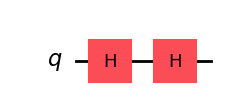

Statevector: [1.+0.j 0.+0.j]
0 amplitud= (1+0j) probabilidad= 1.0 fase (rad)= 0.0


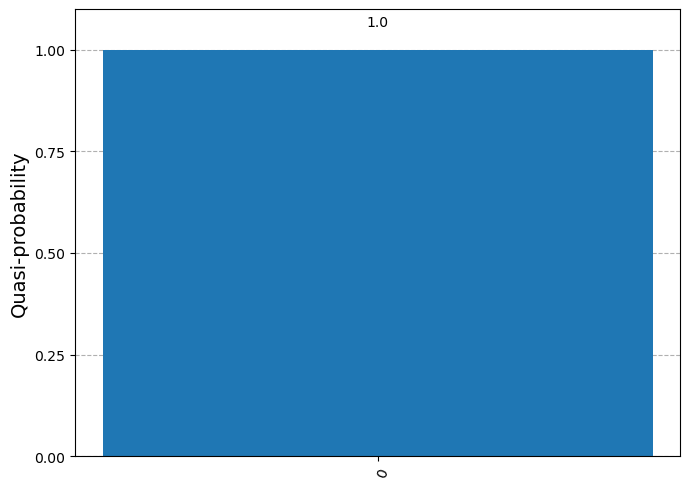

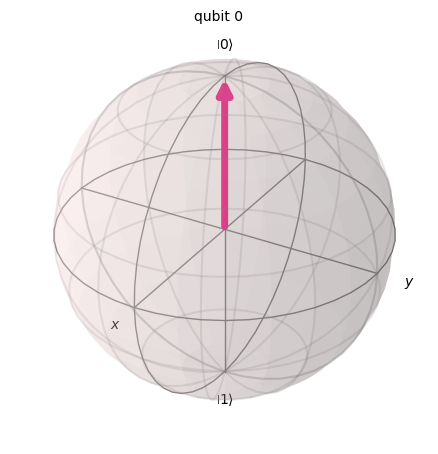

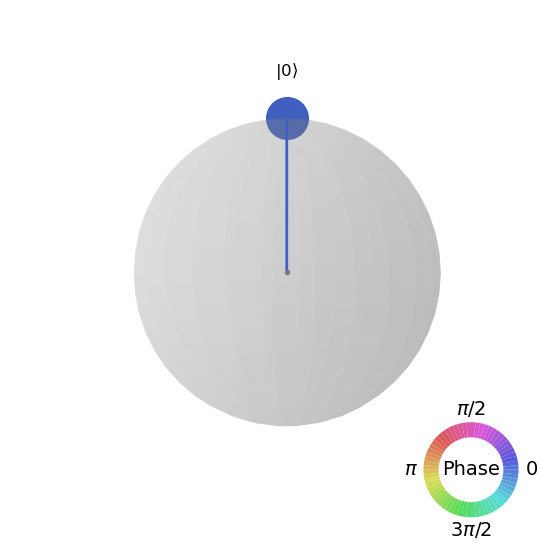

('h', 'z', 'h')


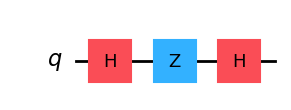

Statevector: [0.+0.j 1.+0.j]
1 amplitud= (1+0j) probabilidad= 1.0 fase (rad)= 0.0


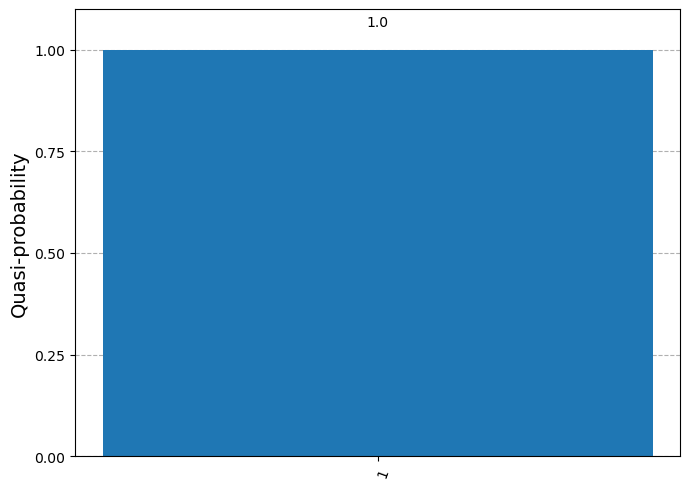

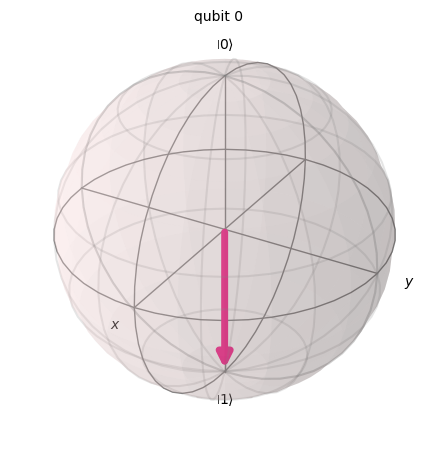

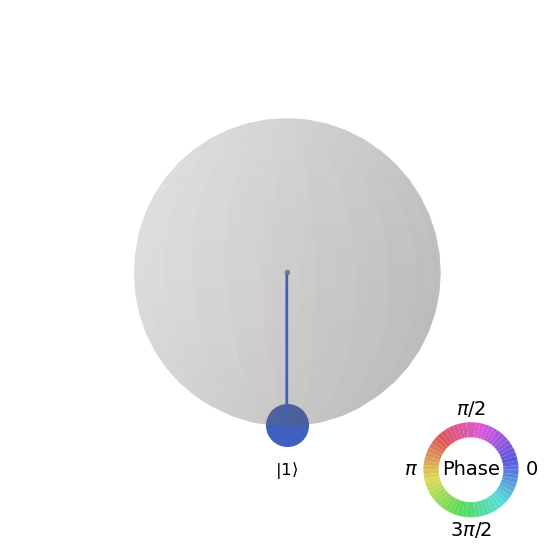

('h', 'z')


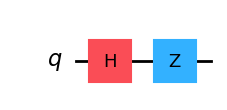

Statevector: [ 0.7071+0.j -0.7071+0.j]
0 amplitud= (0.7071+0j) probabilidad= 0.5 fase (rad)= 0.0
1 amplitud= (-0.7071+0j) probabilidad= 0.5 fase (rad)= 3.1416


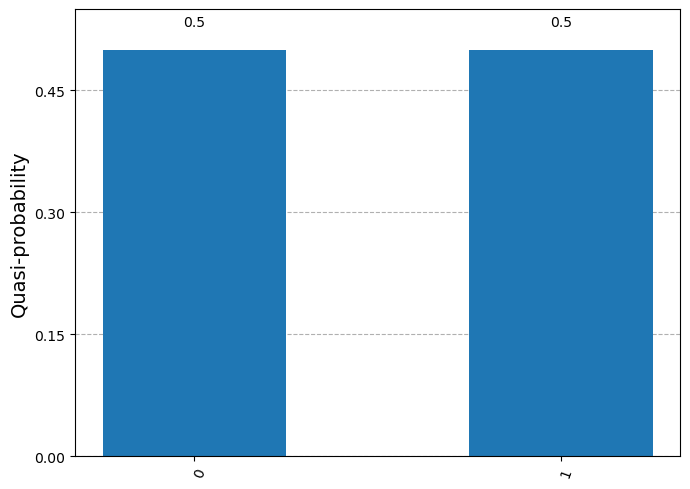

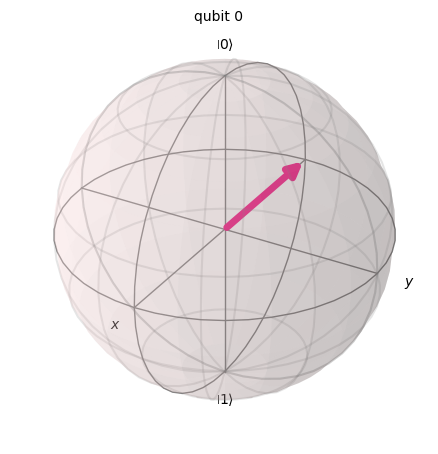

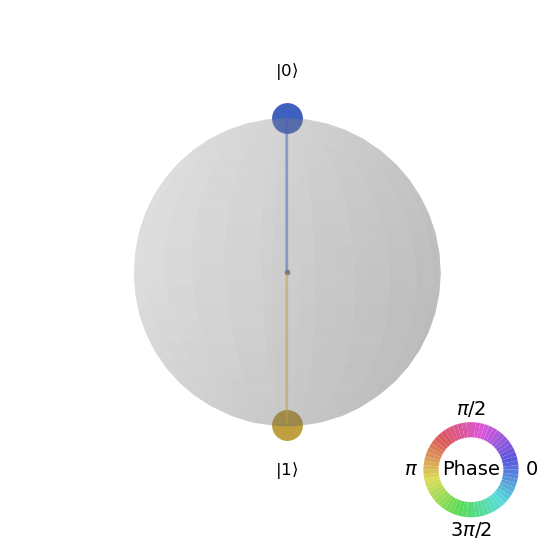

('x', 'y')


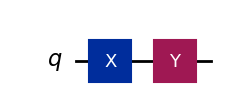

Statevector: [0.-1.j 0.+0.j]
0 amplitud= -1j probabilidad= 1.0 fase (rad)= -1.5708


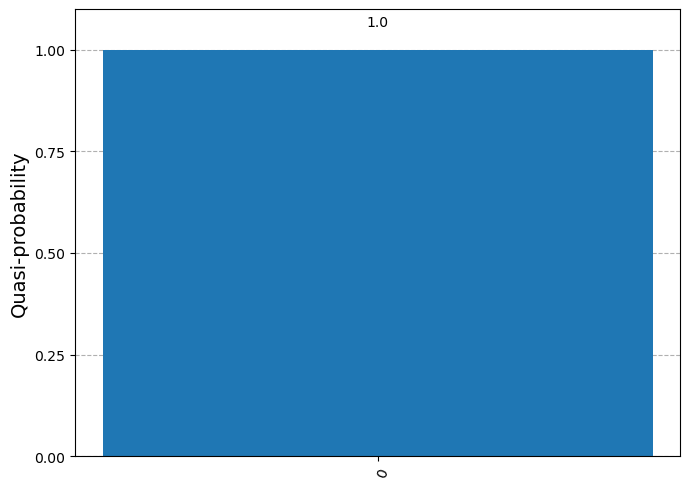

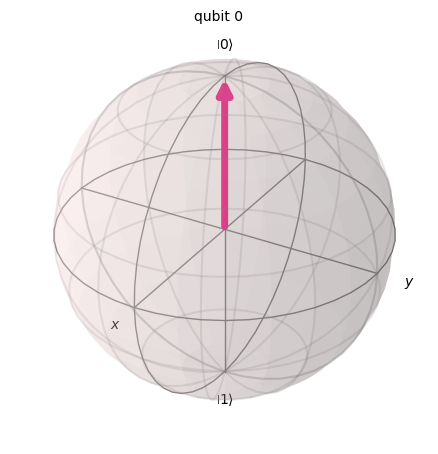

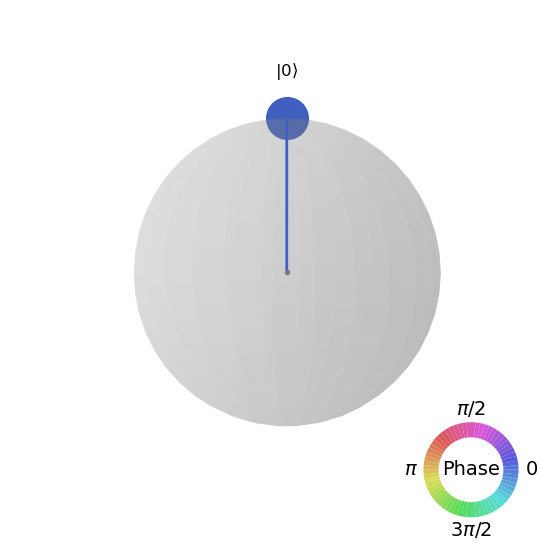

Equivalentes salvo fase global: True


In [32]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
for puertas in [('h','h'),('h','z','h'),('h','z'),('x','y')]:
    q = QuantumCircuit(1)
    for g in puertas: getattr(q,g)(0)
    print(puertas)
    analizar(q)
a = Statevector([1,1]/np.sqrt(2)); b = Statevector(1j*a.data)
print('Equivalentes salvo fase global:', a.equiv(b))

### 3.1. Comparación detallada: H–Z–H y H–Y–H
Las puertas se aplican de izquierda a derecha en el circuito; la matriz total se escribe en orden inverso. Partimos de $|0\rangle$.

| Paso | HZH | HYH |
|---|---|---|
| Inicial | $|0\rangle$ | $|0\rangle$ |
| H | $(|0\rangle+|1\rangle)/\sqrt2$ | $(|0\rangle+|1\rangle)/\sqrt2$ |
| Z o Y | $(|0\rangle-|1\rangle)/\sqrt2$ | $-i(|0\rangle-|1\rangle)/\sqrt2$ |
| H final | $|1\rangle$ | $-i|1\rangle$ |

En ambos casos la puerta intermedia cambia la fase relativa de las dos amplitudes a $\pi$ (módulo $2\pi$). Y añade además una fase global. La última H recombina las amplitudes: se cancelan las contribuciones a $|0\rangle$ y se refuerzan las de $|1\rangle$.

Vamos a mostrar el circuito completo y el estado después de **cada puerta**, sin realizar mediciones intermedias. Las visualizaciones corresponden a prefijos independientes del circuito, no a mediciones físicas del mismo qubit.

In [ ]:
for nombre, puertas in [('HZH', ['h','z','h']), ('HYH', ['h','y','h'])]:
    prefijo = QuantumCircuit(1, name=nombre)
    for puerta in puertas:
        getattr(prefijo, puerta)(0)
        print(f'{nombre}: después de {prefijo.size()} puerta(s)')
        estado = analizar(prefijo)
        display(estado.draw('latex'))
    print('Matriz del circuito:', np.round(Operator(prefijo).data, 4))
    print('Mediciones finales:')
    medir(prefijo)


#### Interpretación de los resultados
- **Statevector:** HZH termina en `[0, 1]`; HYH en `[0, -1j]`. La unidad imaginaria de Python `j` equivale a $i$. La diferencia entre estos estados finales es una fase global, no una diferencia física observable.
- **QSphere:** tras la primera H aparecen dos componentes equiprobables. Tras Z o Y sus fases relativas son opuestas. Al final queda únicamente $|1\rangle$. Qiskit puede normalizar la fase global de la QSphere, por lo que los colores de ambos estados finales pueden ser idénticos.
- **Bloch:** el vector pasa del polo norte al eje +X, luego al eje −X y finalmente al polo sur, en ambos circuitos.
- **Probabilidades y mediciones:** 50 % para cada resultado tras las dos primeras puertas y 100 % para 1 tras la última H. La fase de una amplitud nula no está definida.

**Importante:** que ambos circuitos produzcan el mismo resultado al partir de cero no significa que sean puertas equivalentes para cualquier entrada. $HZH=X$ y $HYH=-Y$. Por ejemplo, sobre $|+\rangle$ producen estados ortogonales. Vamos a comprobarlo.

In [ ]:
hzh = QuantumCircuit(1); hzh.h(0); hzh.z(0); hzh.h(0)
hyh = QuantumCircuit(1); hyh.h(0); hyh.y(0); hyh.h(0)
x_ref = QuantumCircuit(1); x_ref.x(0)
y_ref = QuantumCircuit(1); y_ref.y(0)
assert np.allclose(Operator(hzh).data, Operator(x_ref).data)
assert np.allclose(Operator(hyh).data, -Operator(y_ref).data)
entrada_plus = Statevector([1, 1] / np.sqrt(2))
s_hzh = entrada_plus.evolve(hzh)
s_hyh = entrada_plus.evolve(hyh)
print('Equivalencia desde |0>:', Statevector(hzh).equiv(Statevector(hyh)))
print('Solapamiento desde |+>:', abs(np.vdot(s_hzh.data, s_hyh.data)))
assert np.isclose(abs(np.vdot(s_hzh.data, s_hyh.data)), 0)
for nombre, estado in [('HZH', s_hzh), ('HYH', s_hyh)]:
    print(nombre, 'sobre |+>'); display(estado.draw('latex')); display(plot_bloch_multivector(estado))

## 4. Puertas multiqubit
CNOT, CZ, SWAP y Toffoli. Comprobación de las tablas de verdad sobre estados de base; CZ se distingue por su fase.

#### Control y tablas de verdad

**Qué vamos a hacer y por qué.** CX aplica X al objetivo cuando el control vale uno; CZ introduce un signo negativo en |11⟩; SWAP intercambia los dos cables; CCX aplica X al objetivo cuando ambos controles valen uno. Statevector.from_int prepara cada entrada de la base computacional.

**Qué debes observar al ejecutar la celda.** Lee las cadenas de derecha a izquierda para localizar q0. CZ conserva las cadenas de bits pero cambia una amplitud; su efecto no se detecta con una tabla clásica de probabilidades.

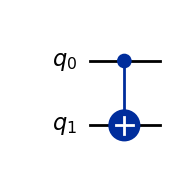

00 -> {'00': (1+0j)}
01 -> {'11': (1+0j)}
10 -> {'10': (1+0j)}
11 -> {'01': (1+0j)}


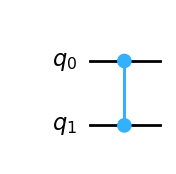

00 -> {'00': (1+0j)}
01 -> {'01': (1+0j)}
10 -> {'10': (1+0j)}
11 -> {'11': (-1+0j)}


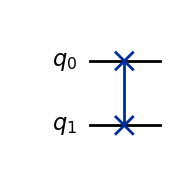

00 -> {'00': (1+0j)}
01 -> {'10': (1+0j)}
10 -> {'01': (1+0j)}
11 -> {'11': (1+0j)}


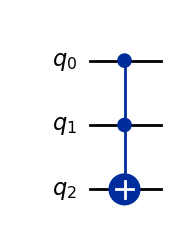

000 -> {'000': (1+0j)}
001 -> {'001': (1+0j)}
010 -> {'010': (1+0j)}
011 -> {'111': (1+0j)}
100 -> {'100': (1+0j)}
101 -> {'101': (1+0j)}
110 -> {'110': (1+0j)}
111 -> {'011': (1+0j)}


In [35]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
for nombre, n, args in [('cx',2,(0,1)),('cz',2,(0,1)),('swap',2,(0,1)),('ccx',3,(0,1,2))]:
    q = QuantumCircuit(n); getattr(q,nombre)(*args)
    display(q.draw('mpl'))
    for i in range(2**n):
        out=Statevector.from_int(i,2**n).evolve(q)
        print(format(i,f'0{n}b'), '->', out.to_dict())

## 5. Entrelazamiento
Bell: 00 y 11 con igual probabilidad. GHZ: 000 y 111. Las esferas de Bloch individuales pueden mostrar vectores nulos aunque el estado global sea puro.

#### Correlaciones y estados reducidos

**Qué vamos a hacer y por qué.** H y CX preparan una superposición de |00⟩ y |11⟩. Una CX adicional extiende el patrón a GHZ. El estado global no puede escribirse como producto de estados individuales. partial_trace elimina matemáticamente los subsistemas no observados.

**Qué debes observar al ejecutar la celda.** En Bell aparecen 00 y 11; en GHZ, 000 y 111. Los estados locales son I/2, de modo que sus vectores de Bloch tienen longitud cero. Una correlación en Z por sí sola no demuestra entrelazamiento.

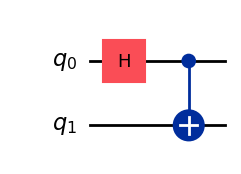

Statevector: [0.7071+0.j 0.    +0.j 0.    +0.j 0.7071+0.j]
00 amplitud= (0.7071+0j) probabilidad= 0.5 fase (rad)= 0.0
11 amplitud= (0.7071+0j) probabilidad= 0.5 fase (rad)= 0.0


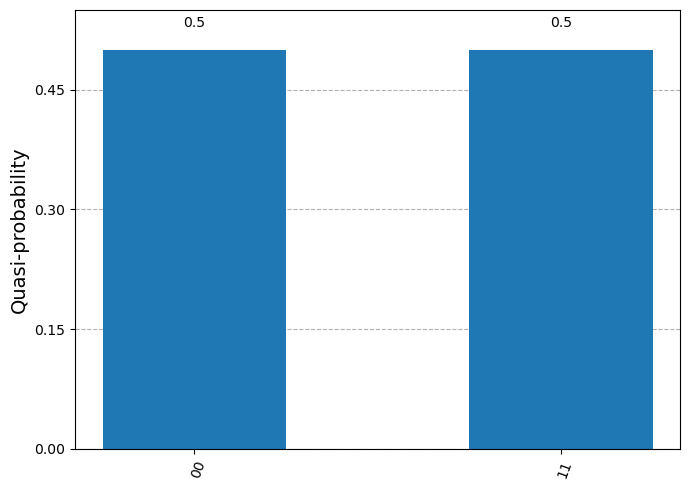

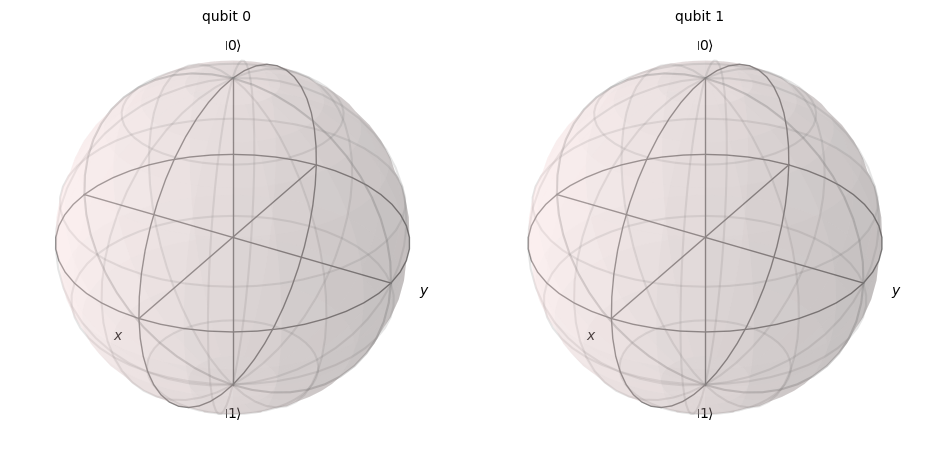

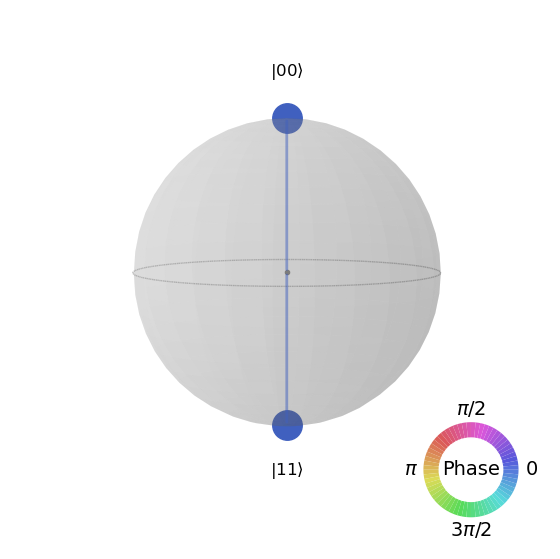

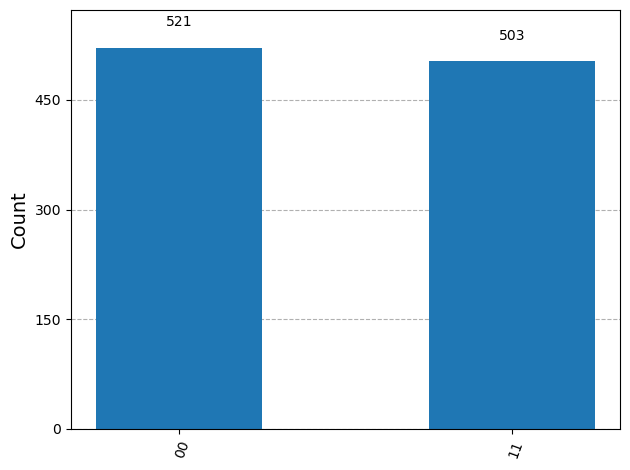

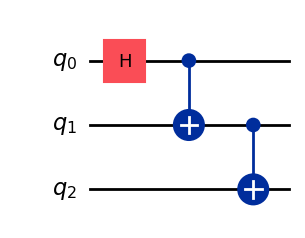

Statevector: [0.7071+0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j
 0.    +0.j 0.7071+0.j]
000 amplitud= (0.7071+0j) probabilidad= 0.5 fase (rad)= 0.0
111 amplitud= (0.7071+0j) probabilidad= 0.5 fase (rad)= 0.0


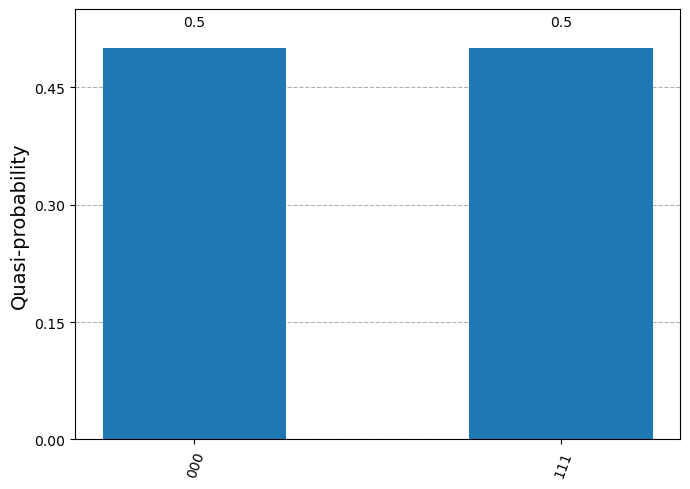

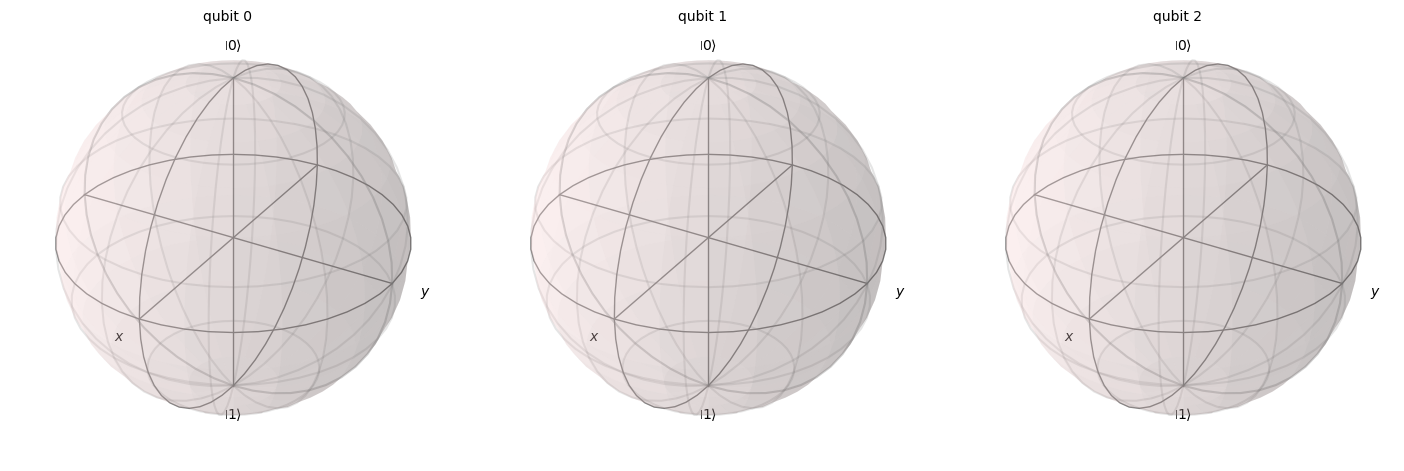

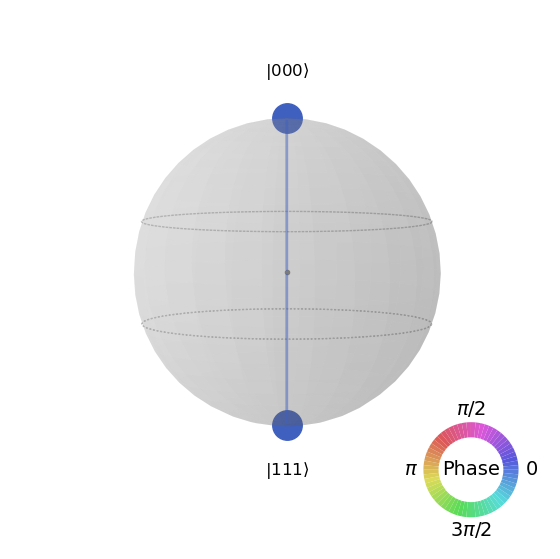

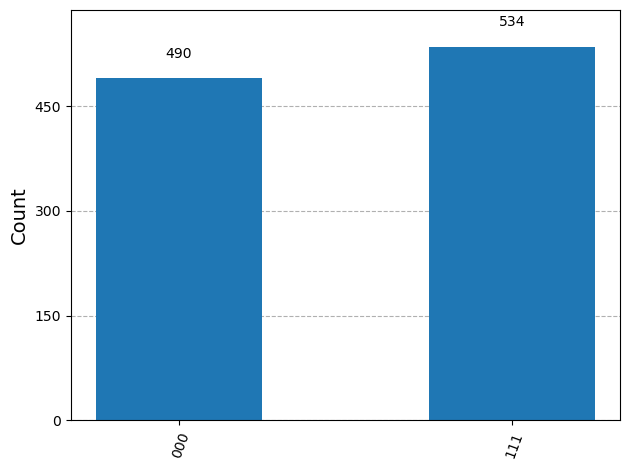

Estado reducido de q0: [[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]]


In [38]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
bell = QuantumCircuit(2); bell.h(0); bell.cx(0,1)
ghz = QuantumCircuit(3); ghz.h(0); ghz.cx(0,1); ghz.cx(1,2)
for q in [bell,ghz]:
    analizar(q); medir(q)
print('Estado reducido de q0:', partial_trace(Statevector.from_instruction(bell),[1]).data)

### 5.1. Los cuatro estados de Bell
Los cuatro estados forman una base ortonormal del espacio de dos qubits. Todos están máximamente entrelazados; ninguno es un producto de dos estados individuales. Usamos el orden de Qiskit $|q_1q_0\rangle$.

| Estado | Expresión | Puertas después de H(0), CX(0,1) |
|---|---|---|
| $\Phi^+$ | $(|00\rangle+|11\rangle)/\sqrt2$ | Ninguna |
| $\Phi^-$ | $(|00\rangle-|11\rangle)/\sqrt2$ | Z(0) |
| $\Psi^+$ | $(|01\rangle+|10\rangle)/\sqrt2$ | X(1) |
| $\Psi^-$ | $(|01\rangle-|10\rangle)/\sqrt2$ | X(1), después Z(1) |

Todos los estados tienen probabilidad 1/2 en cada término de su expresión. El signo relativo no cambia el histograma en Z.

#### Preparación de la base de Bell

**Qué vamos a hacer y por qué.** Partimos de Φ+. X en q1 intercambia los patrones de paridad; Z modifica el signo relativo. Las cuatro combinaciones generan estados ortogonales. Se conservan los circuitos y vectores en diccionarios para reutilizarlos.

**Qué debes observar al ejecutar la celda.** Φ± tienen soporte 00 y 11; Ψ± tienen soporte 01 y 10. Los signos no cambian esas probabilidades, pero sí la fase en QSphere. Todas las esferas de Bloch individuales tienen vector nulo.

Phi+


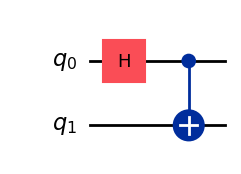

Statevector: [0.7071+0.j 0.    +0.j 0.    +0.j 0.7071+0.j]
00 amplitud= (0.7071+0j) probabilidad= 0.5 fase (rad)= 0.0
11 amplitud= (0.7071+0j) probabilidad= 0.5 fase (rad)= 0.0


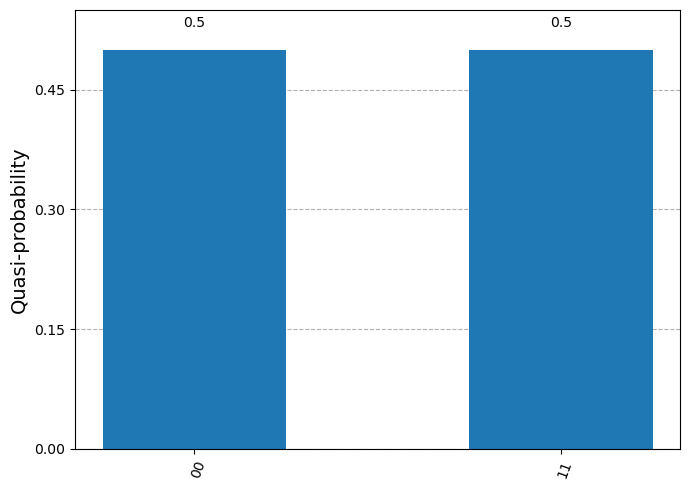

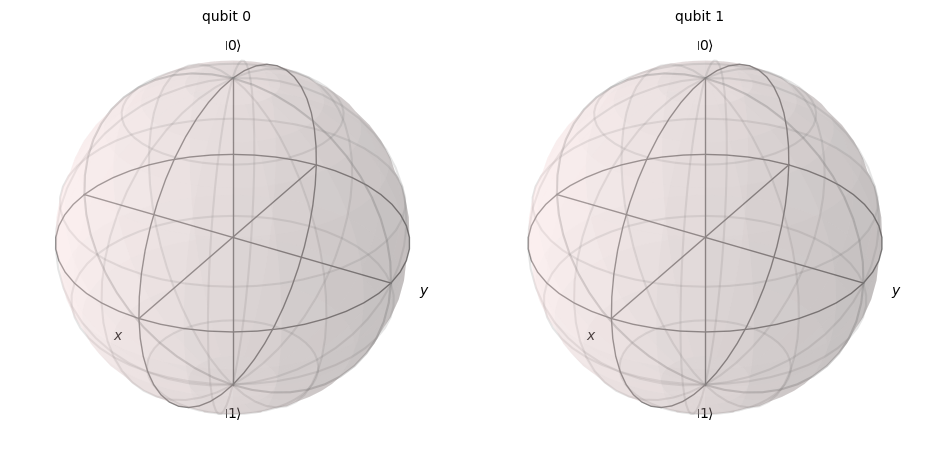

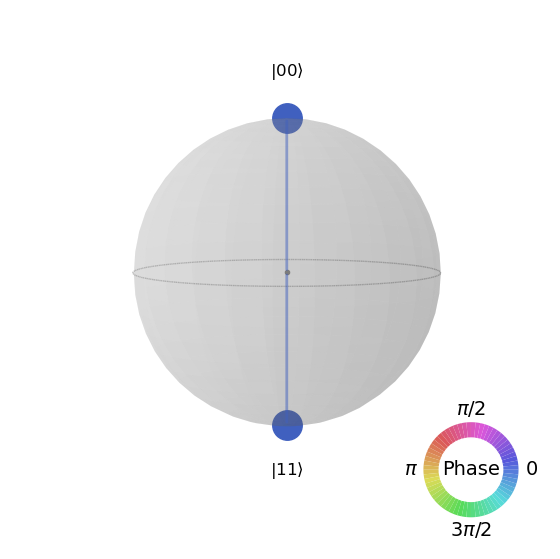

<IPython.core.display.Latex object>

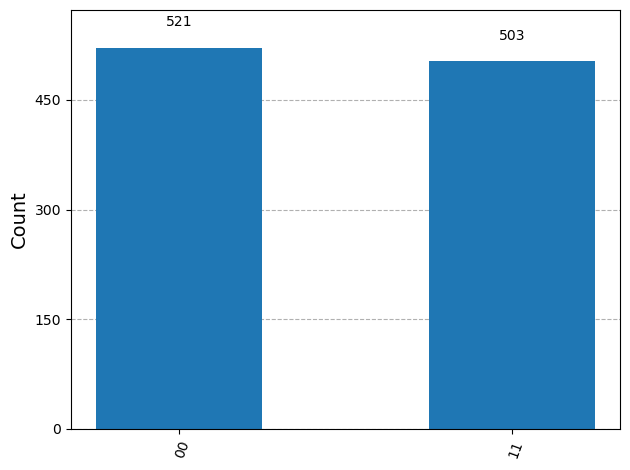

Phi-


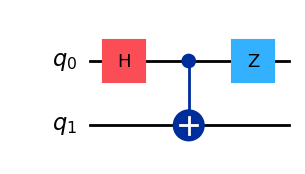

Statevector: [ 0.7071+0.j  0.    +0.j  0.    +0.j -0.7071+0.j]
00 amplitud= (0.7071+0j) probabilidad= 0.5 fase (rad)= 0.0
11 amplitud= (-0.7071+0j) probabilidad= 0.5 fase (rad)= 3.1416


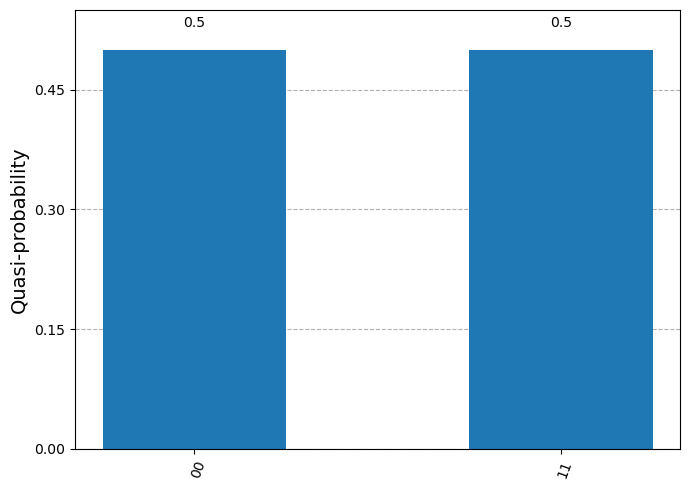

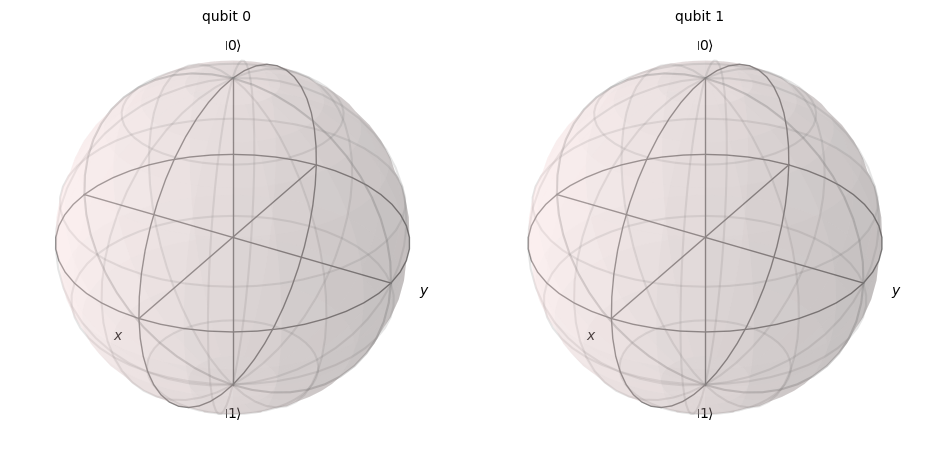

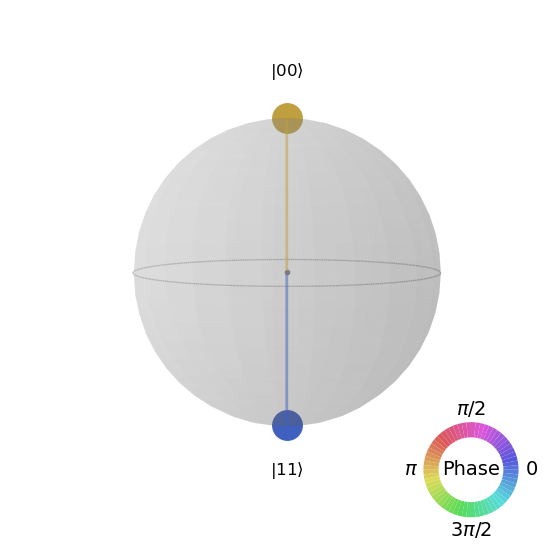

<IPython.core.display.Latex object>

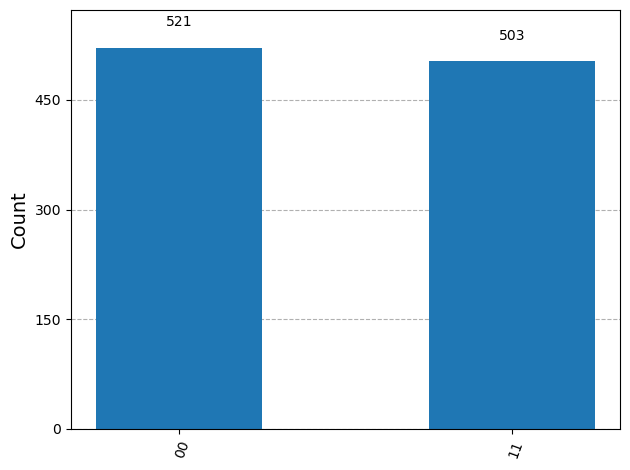

Psi+


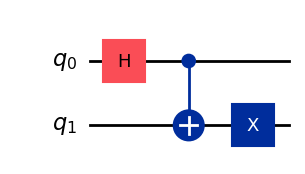

Statevector: [0.    +0.j 0.7071+0.j 0.7071+0.j 0.    +0.j]
01 amplitud= (0.7071+0j) probabilidad= 0.5 fase (rad)= 0.0
10 amplitud= (0.7071+0j) probabilidad= 0.5 fase (rad)= 0.0


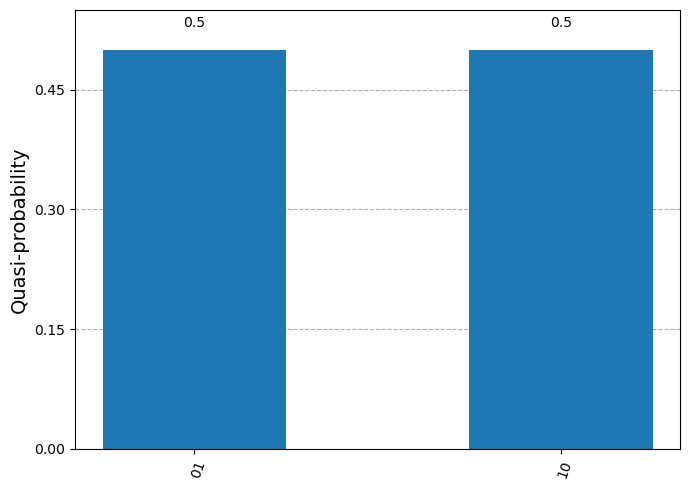

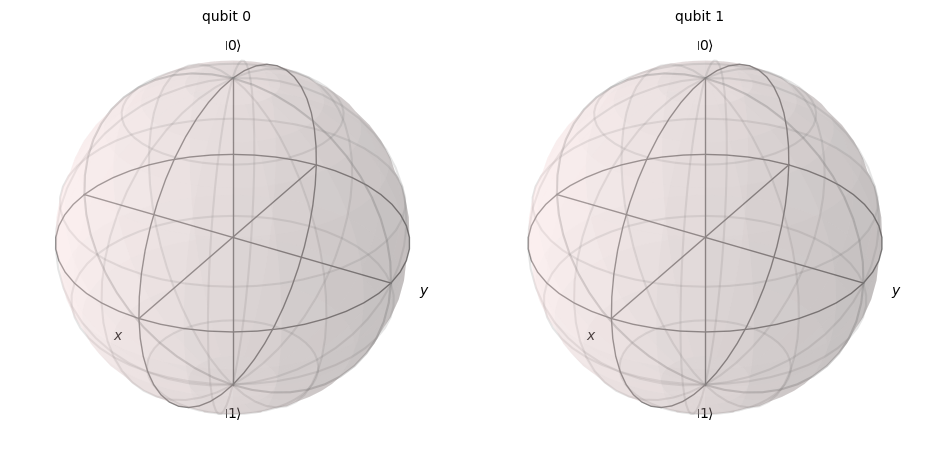

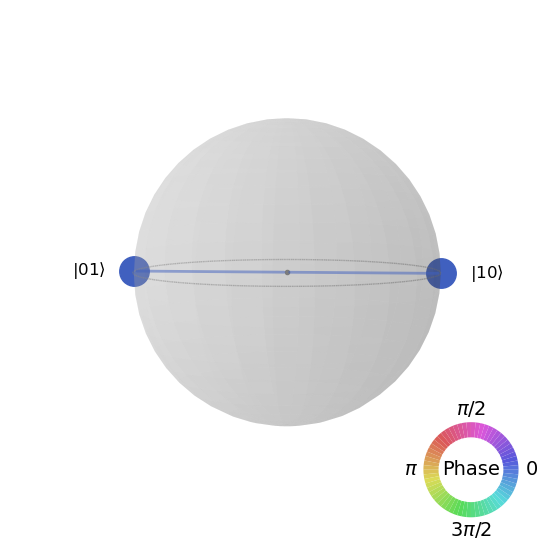

<IPython.core.display.Latex object>

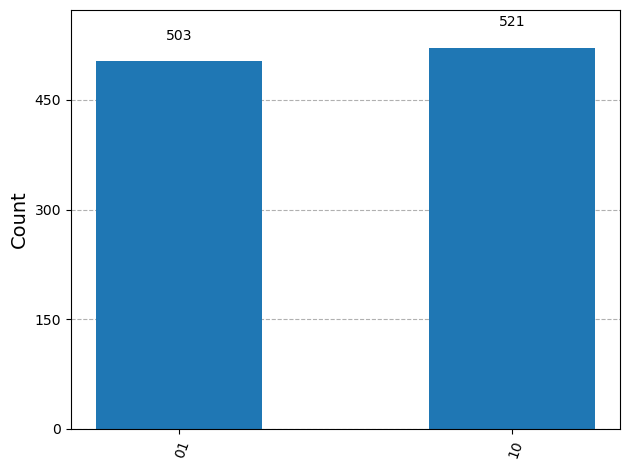

Psi-


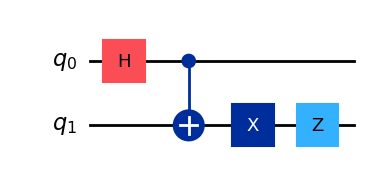

Statevector: [ 0.    +0.j  0.7071+0.j -0.7071+0.j  0.    +0.j]
01 amplitud= (0.7071+0j) probabilidad= 0.5 fase (rad)= 0.0
10 amplitud= (-0.7071+0j) probabilidad= 0.5 fase (rad)= 3.1416


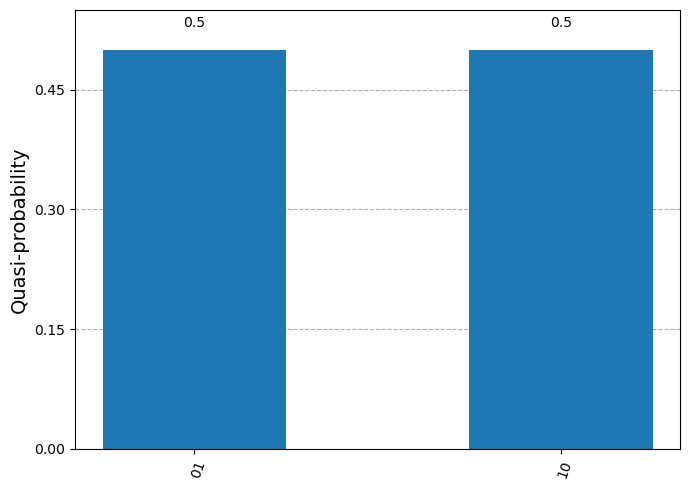

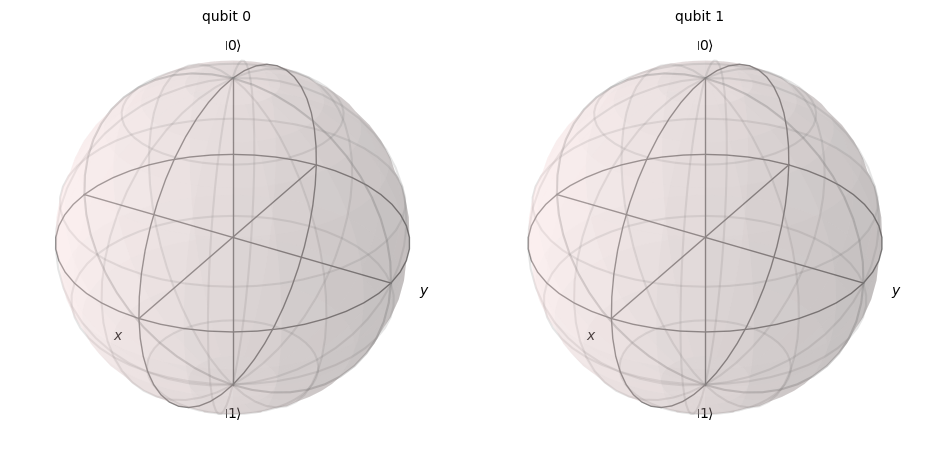

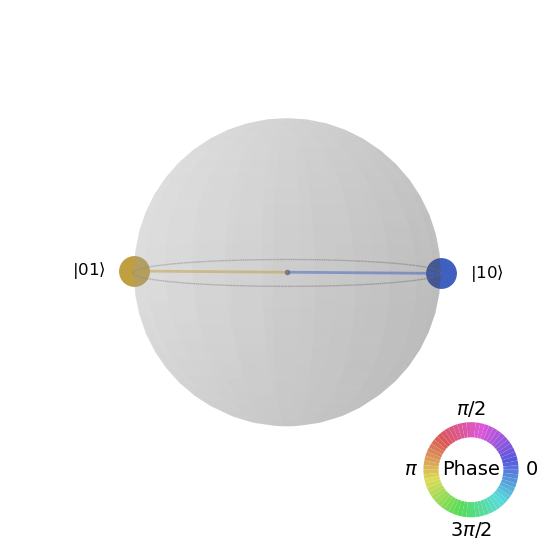

<IPython.core.display.Latex object>

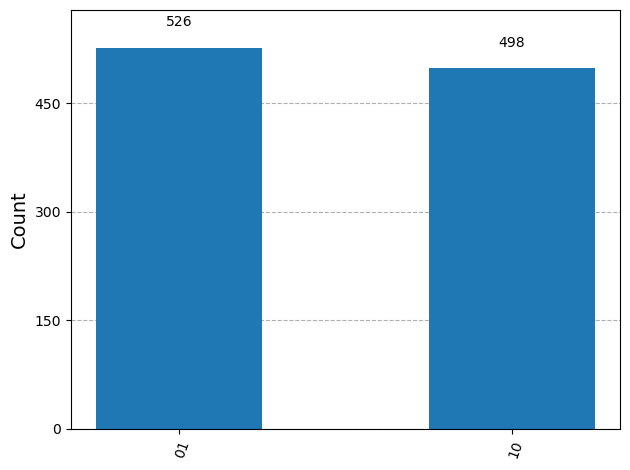

In [41]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
bell_circuits = {}
for nombre, bit_flip, phase_flip in [('Phi+',0,0),('Phi-',0,1),('Psi+',1,0),('Psi-',1,1)]:
    qc_bell = QuantumCircuit(2, name=nombre)
    qc_bell.h(0)
    qc_bell.cx(0,1)
    if bit_flip: qc_bell.x(1)
    if phase_flip: qc_bell.z(1 if bit_flip else 0)
    bell_circuits[nombre] = qc_bell
bell_vectors = {}
for nombre, qc_bell in bell_circuits.items():
    print(nombre)
    sv_bell = analizar(qc_bell)
    display(sv_bell.draw('latex'))
    bell_vectors[nombre] = sv_bell
    medir(qc_bell)


### 5.2. Comparación matemática y entrelazamiento
La matriz de Gram contiene los productos internos $\langle B_i|B_j\rangle$. Debe ser la identidad. Cada estado global es puro, pero cada qubit por separado tiene matriz de densidad $I/2$ y pureza $1/2$. Por eso sus vectores de Bloch son nulos: no significa que el sistema global carezca de información.

#### Ortogonalidad y pureza

**Qué vamos a hacer y por qué.** La matriz B reúne los cuatro vectores como columnas. B†B contiene productos internos: la diagonal vale uno y el resto cero. La pureza Tr(ρ²) vale uno para estados puros y 1/2 para un qubit máximamente mezclado.

**Qué debes observar al ejecutar la celda.** Los assert comprueban las identidades con tolerancia numérica. El estado global de Bell es puro aunque sus subsistemas no lo sean.

In [44]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
B = np.column_stack([v.data for v in bell_vectors.values()])
print('Matriz de Gram:', np.round(B.conj().T @ B, 4))
assert np.allclose(B.conj().T @ B, np.eye(4))
for nombre, v in bell_vectors.items():
    for qubit in [0,1]:
        rho = partial_trace(v, [1-qubit])
        print(nombre, 'q', qubit, 'rho=', np.round(rho.data,3), 'pureza=', np.real(np.trace(rho.data @ rho.data)))
        assert np.allclose(rho.data, np.eye(2)/2)


Matriz de Gram: [[ 1.+0.j -0.+0.j  0.+0.j  0.+0.j]
 [-0.+0.j  1.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  1.+0.j -0.+0.j]
 [ 0.+0.j  0.+0.j -0.+0.j  1.+0.j]]
Phi+ q 0 rho= [[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]] pureza= 0.4999999999999998
Phi+ q 1 rho= [[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]] pureza= 0.4999999999999998
Phi- q 0 rho= [[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]] pureza= 0.4999999999999998
Phi- q 1 rho= [[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]] pureza= 0.4999999999999998
Psi+ q 0 rho= [[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]] pureza= 0.4999999999999998
Psi+ q 1 rho= [[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]] pureza= 0.4999999999999998
Psi- q 0 rho= [[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]] pureza= 0.4999999999999998
Psi- q 1 rho= [[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]] pureza= 0.4999999999999998


### 5.3. Medir en Z y en X
En Z los signos + y − no se distinguen. Para medir en X se aplica H a ambos qubits antes de medir en Z. La correlación cambia según la fase relativa. Las correlaciones por sí solas en una única base no prueban entrelazamiento.

#### Cambiar la base de medida

**Qué vamos a hacer y por qué.** Medir en X equivale a aplicar H antes de medir en Z, porque H transforma los autoestados de X en los de Z. Se comparan probabilidades exactas y muestras aleatorias.

**Qué debes observar al ejecutar la celda.** En Z, Φ tiene paridad par y Ψ impar. En X, los estados con signo + tienen paridad par y los de signo − impar. Comprueba estas diferencias en los histogramas.

Phi+ Z: {'00': 0.4999999999999999, '11': 0.4999999999999999} X: {'00': 0.4999999999999998, '11': 0.4999999999999998}


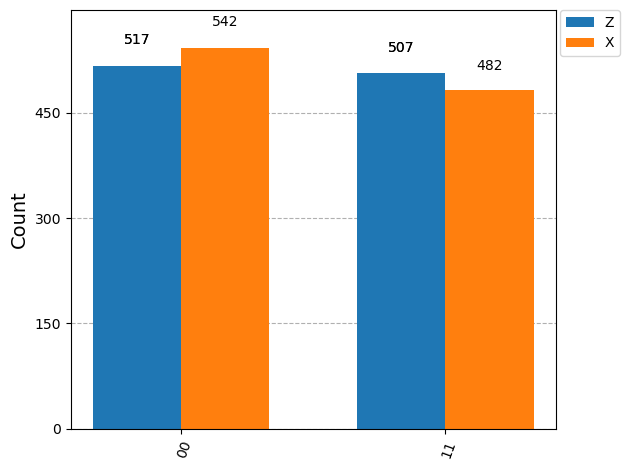

Phi- Z: {'00': 0.4999999999999999, '11': 0.4999999999999999} X: {'01': 0.4999999999999998, '10': 0.4999999999999998}


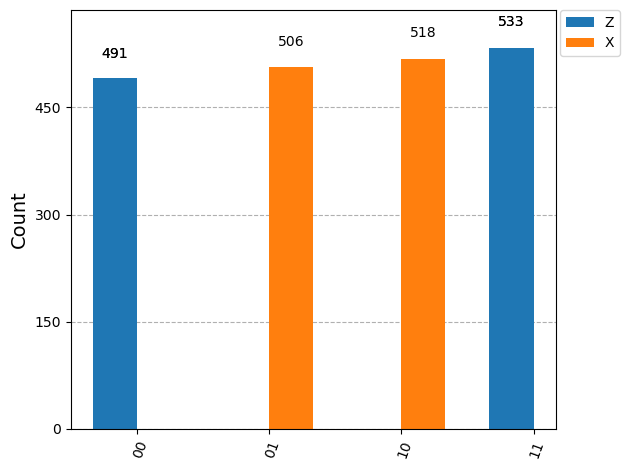

Psi+ Z: {'01': 0.4999999999999999, '10': 0.4999999999999999} X: {'00': 0.4999999999999998, '11': 0.4999999999999998}


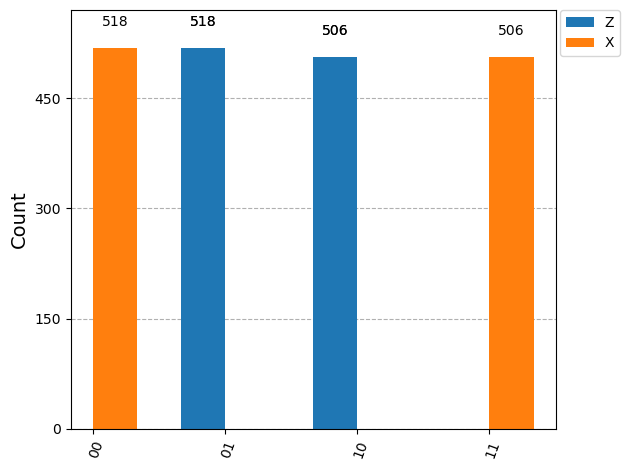

Psi- Z: {'01': 0.4999999999999999, '10': 0.4999999999999999} X: {'01': 0.4999999999999998, '10': 0.4999999999999998}


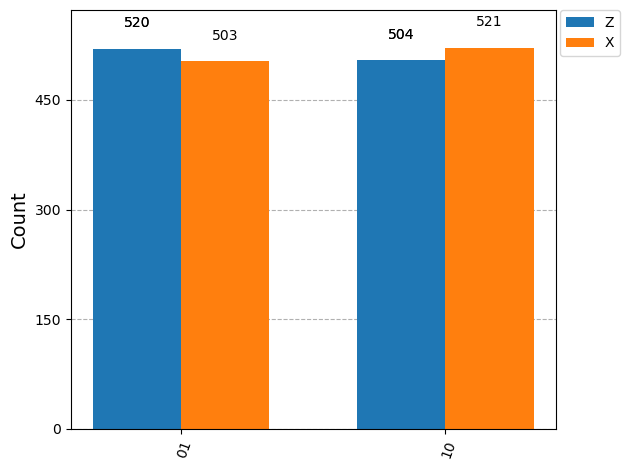

In [47]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
for nombre, qc_bell in bell_circuits.items():
    x_basis = qc_bell.copy()
    x_basis.h([0,1])
    print(nombre, 'Z:', Statevector.from_instruction(qc_bell).probabilities_dict(),
          'X:', Statevector.from_instruction(x_basis).probabilities_dict())
    display(plot_histogram([Statevector.from_instruction(qc_bell).sample_counts(1024),
                            Statevector.from_instruction(x_basis).sample_counts(1024)], legend=['Z','X']))


### 5.4. Ejercicio: analizador de Bell
Aplica CX(0,1) y H(0) a cada estado. Predice el resultado determinista y compruébalo. Este circuito transforma la base de Bell en la base computacional.

#### Decodificación de Bell

**Qué vamos a hacer y por qué.** El inverso de H seguida de CX es CX seguida de H. Aplicarlo a los cuatro estados transforma sus diferencias de fase y paridad en bits distinguibles.

**Qué debes observar al ejecutar la celda.** En orden q1q0 se esperan Φ+: 00, Φ−: 01, Ψ+: 10 y Ψ−: 11, salvo errores numéricos. El resultado permite identificar el estado de Bell ideal.

Phi+ {'00': 0.9999999999999996}


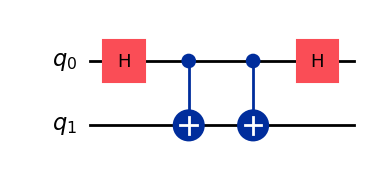

Phi- {'01': 0.9999999999999996}


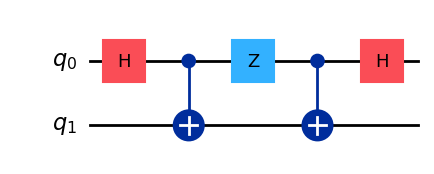

Psi+ {'10': 0.9999999999999996}


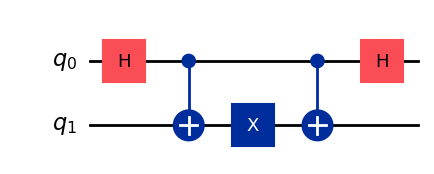

Psi- {'11': 0.9999999999999996}


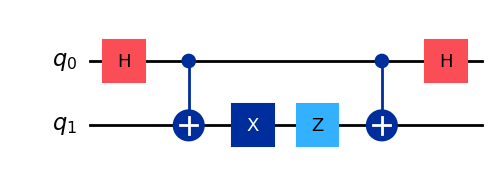

In [50]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
for nombre, qc_bell in bell_circuits.items():
    decoder = qc_bell.copy()
    decoder.cx(0,1); decoder.h(0)
    print(nombre, Statevector.from_instruction(decoder).probabilities_dict())
    display(decoder.draw('mpl'))


## 6. Medición intermedia
H–medición–H–medición. El resultado final no es necesariamente cero, a diferencia de HH sin medición. Usamos Aer porque StatevectorSampler no admite mediciones intermedias.

#### Medición intermedia

**Qué vamos a hacer y por qué.** La primera medición proyecta el estado y registra el resultado en c0. H vuelve a crear superposición a partir de ese resultado; la segunda medida se guarda en c1. Aer puede simular esta secuencia no unitaria.

**Qué debes observar al ejecutar la celda.** Se esperan cuatro pares de bits aproximadamente equiprobables. Sin medida intermedia HH devuelve cero. StatevectorSampler se utiliza aquí únicamente con medición final.

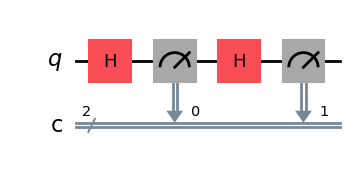

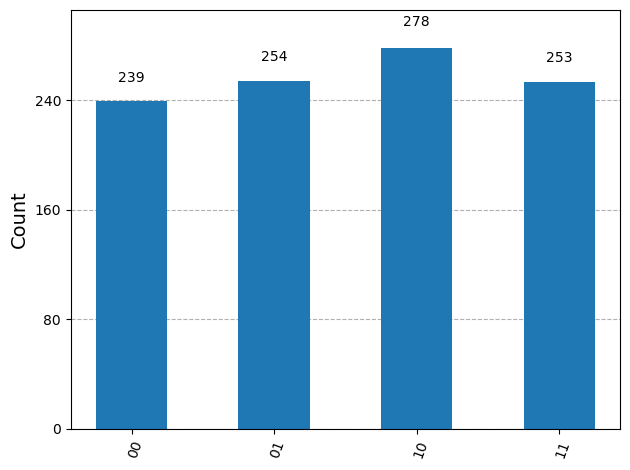

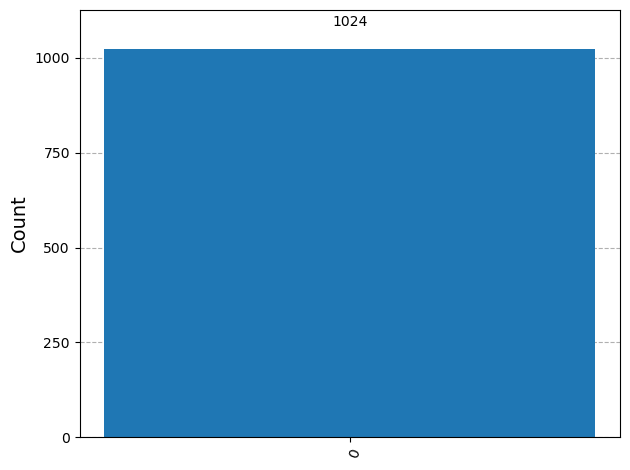

{'11': 509, '00': 515}


In [53]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
q = QuantumCircuit(1,2)
q.h(0); q.measure(0,0); q.h(0); q.measure(0,1)
display(q.draw('mpl')); medir(q)
q2=QuantumCircuit(1); q2.h(0); q2.h(0); medir(q2)
# Muestreo ideal de un circuito con medición final
sample=bell.copy(); sample.measure_all()
print(StatevectorSampler(seed=42).run([sample],shots=SHOTS).result()[0].data.meas.get_counts())

## 7. Aritmética reversible
Semisumador: S=A XOR B y C=A AND B. Sumador completo: S=A XOR B XOR Cin; Cout=AB XOR ACin XOR BCin. Se conservan las entradas y las salidas empiezan en cero.

#### Sumadores reversibles

**Qué vamos a hacer y por qué.** CX calcula XOR sobre un destino inicializado a cero y CCX calcula AND. El acarreo completo es la paridad de los tres productos por parejas. Mantener las entradas permite construir una transformación reversible.

**Qué debes observar al ejecutar la celda.** Para 1+1 el resultado es suma 0 y acarreo 1; para 1+1+1 es suma 1 y acarreo 1. Comprueba todas las entradas y recuerda el orden de cables al leer las cadenas.

0 0 None -> carry,sum: 00
1 0 None -> carry,sum: 01
0 1 None -> carry,sum: 01
1 1 None -> carry,sum: 10


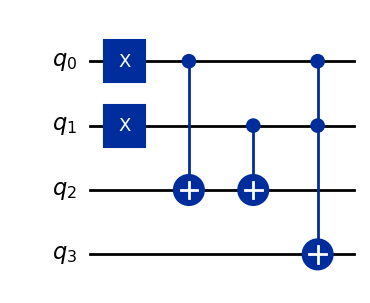

0 0 0 -> carry,sum: 00
1 0 0 -> carry,sum: 01
0 1 0 -> carry,sum: 01
1 1 0 -> carry,sum: 10
0 0 1 -> carry,sum: 01
1 0 1 -> carry,sum: 10
0 1 1 -> carry,sum: 10
1 1 1 -> carry,sum: 11


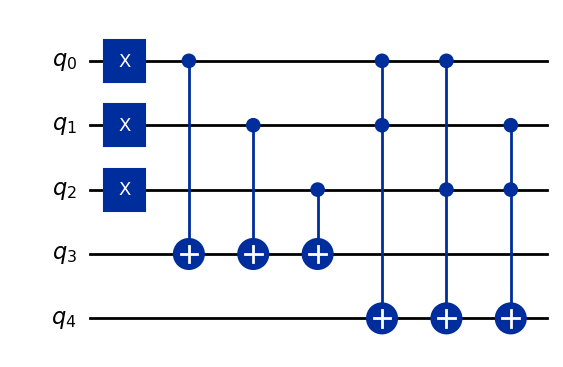

In [56]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
def sumador(a,b,cin=None):
    full=cin is not None
    q=QuantumCircuit(5 if full else 4)
    valores=[a,b,cin] if full else [a,b]
    for i,v in enumerate(valores):
        if v: q.x(i)
    s,carry=(3,4) if full else (2,3)
    for i in range(len(valores)): q.cx(i,s)
    q.ccx(0,1,carry)
    if full:
        q.ccx(0,2,carry); q.ccx(1,2,carry)
    return q
for full in [False,True]:
    for i in range(8 if full else 4):
        a,b=i&1,(i>>1)&1; cin=(i>>2)&1 if full else None
        q=sumador(a,b,cin); sv=Statevector.from_instruction(q)
        k=max(sv.probabilities_dict(),key=sv.probabilities_dict().get)
        total=a+b+(cin or 0)
        assert int(k[0])*2+int(k[1])==total
        print(a,b,cin,'-> carry,sum:',k[:2])
    display(q.draw('mpl'))

### 7.1. Semisumador cuántico: circuito independiente
El semisumador suma dos bits A y B. Produce dos bits: suma $S=A\oplus B$ y acarreo $C=A B$. El valor decimal es $2C+S$.

Utilizamos cuatro qubits: A=q0, B=q1, S=q2, C=q3. Los dos últimos comienzan en cero. Dos CNOT acumulan el XOR en S y una Toffoli escribe el AND en C. Las entradas se conservan: esto garantiza que la transformación sea reversible. Si los destinos no empiezan en cero, las puertas acumulan XOR sobre su valor previo.

El circuito del sumador se construye separado de la preparación de entradas para poder reutilizarlo. El orden de lectura de Qiskit es **C S B A**.

In [ ]:
from itertools import product

def semisumador_cuantico():
    q = QuantumCircuit(4, name='Semisumador')
    q.cx(0, 2)
    q.cx(1, 2)
    q.ccx(0, 1, 3)
    return q

half = semisumador_cuantico()
display(half.draw('mpl', style={'backgroundcolor':'#EAF4FA'}))
print('A B | C S | decimal')
for a,b in product([0,1], repeat=2):
    prep = QuantumCircuit(4)
    if a: prep.x(0)
    if b: prep.x(1)
    circuito_half = prep.compose(half)
    estado_half = Statevector.from_instruction(circuito_half)
    bits = max(estado_half.probabilities_dict(), key=estado_half.probabilities_dict().get)
    carry, suma = map(int, bits[:2])
    assert (carry,suma) == ((a+b)//2,(a+b)%2)
    print(a,b,'|',carry,suma,'|',2*carry+suma)
# Ejemplo: 1 + 1 = 10 en binario
print('Ejemplo A=B=1:')
analizar(circuito_half)
medir(circuito_half)

#### Tabla de verdad e interpretación del semisumador
| A | B | C | S |
|---|---|---|---|
|0|0|0|0|
|0|1|0|1|
|1|0|0|1|
|1|1|1|0|

Para A=B=1, el estado final es $|1011\rangle$ (orden CSBA). Las dos CNOT invierten S dos veces, por lo que vuelve a cero. La Toffoli invierte C una vez porque ambas entradas valen uno. El resultado aritmético es `10`, es decir, 2; la cadena completa incluye también las entradas conservadas. La QSphere tiene un único componente y las esferas de Bloch muestran estados de base.

### 7.2. Sumador completo cuántico
Añadimos un tercer bit de entrada, $C_{in}$, para poder sumar cifras de varias posiciones binarias. Usamos cinco qubits: A=q0, B=q1, Cin=q2, S=q3 y Cout=q4. Los dos destinos se inicializan en cero.

$$S=A\oplus B\oplus C_{in}$$
$$C_{out}=AB\oplus AC_{in}\oplus BC_{in}$$

Tres CNOT calculan la paridad de las entradas. Tres Toffoli calculan el acarreo: si hay dos unos se activa exactamente un producto; si hay tres unos se activan tres productos, cuya paridad también es uno. Esta expresión es equivalente a la función mayoría para tres bits. El valor decimal es $2C_{out}+S$.

El orden de lectura es **Cout S Cin B A**. No confundas el acarreo de entrada con el de salida.

In [ ]:
def sumador_completo_cuantico():
    q = QuantumCircuit(5, name='Sumador completo')
    for control in [0,1,2]:
        q.cx(control, 3)
    for i,j in [(0,1),(0,2),(1,2)]:
        q.ccx(i,j,4)
    return q

full_adder = sumador_completo_cuantico()
display(full_adder.draw('mpl', style={'backgroundcolor':'#FFF4E0'}))
print('A B Cin | Cout S | decimal')
for a,b,cin in product([0,1], repeat=3):
    prep = QuantumCircuit(5)
    for i,bit in enumerate([a,b,cin]):
        if bit: prep.x(i)
    circuito_full = prep.compose(full_adder)
    estado_full = Statevector.from_instruction(circuito_full)
    bits = max(estado_full.probabilities_dict(), key=estado_full.probabilities_dict().get)
    carry,suma = map(int,bits[:2])
    total = a+b+cin
    assert (carry,suma) == (total//2,total%2)
    print(a,b,cin,'|',carry,suma,'|',total)
print('Ejemplo A=B=Cin=1:')
analizar(circuito_full)
medir(circuito_full)

#### Tabla de verdad e interpretación del sumador completo
| A | B | Cin | Cout | S |
|---|---|---|---|---|
|0|0|0|0|0|
|0|0|1|0|1|
|0|1|0|0|1|
|0|1|1|1|0|
|1|0|0|0|1|
|1|0|1|1|0|
|1|1|0|1|0|
|1|1|1|1|1|

Para 1+1+1 obtenemos $|11111\rangle$: S=1 y Cout=1, resultado binario `11` (decimal 3). Con entradas clásicas ideales la salida es determinista. Las puertas CNOT y Toffoli son reversibles; no necesitamos medir durante el cálculo.

### 7.3. ¿Qué ocurre con entradas en superposición?
Ahora aplicamos H a todas las entradas del semisumador y del sumador completo, dejando los destinos en cero. Los circuitos actúan linealmente sobre todas las componentes de la superposición. Observa la QSphere y el histograma marginal de los dos bits de resultado (acarreo, suma). En cada medición obtenemos un único resultado, no toda la tabla de verdad. Esto no demuestra una ventaja cuántica. Los registros de entrada y salida pueden quedar entrelazados.

In [ ]:
for nombre, bloque, n_in in [('Semisumador',half,2),('Sumador completo',full_adder,3)]:
    prep = QuantumCircuit(bloque.num_qubits)
    prep.h(list(range(n_in)))
    compuesto = prep.compose(bloque)
    print(nombre, 'con entradas en superposición')
    estado = analizar(compuesto)
    probs = estado.probabilities_dict(qargs=[n_in,n_in+1])
    print('Probabilidades marginales (acarreo, suma):', probs)
    display(plot_distribution(probs))
    esperado = [1/4,1/2,1/4,0] if n_in==2 else [1/8,3/8,3/8,1/8]
    assert np.allclose(estado.probabilities([n_in,n_in+1]), esperado)
    # Aplicamos el inverso sin medir para recuperar las entradas y limpiar las salidas.
    recuperado = compuesto.compose(bloque.inverse())
    assert Statevector(recuperado).equiv(Statevector(prep))

## 8. Grover
Oráculo: invierte la fase de las soluciones. Difusor: reflexión respecto al estado uniforme. Para N=4 y M=1, una iteración ideal encuentra la solución con probabilidad 1.

#### Búsqueda por amplificación de amplitud

**Qué vamos a hacer y por qué.** H prepara una distribución uniforme. El oráculo invierte la fase de la solución sin medir. El difusor refleja amplitudes respecto a su media (hasta una fase global según la implementación). La interferencia amplifica la solución.

**Qué debes observar al ejecutar la celda.** Con cuatro candidatos y una solución, una iteración ideal concentra toda la probabilidad en 10. El oráculo presupone una forma de reconocer soluciones; su coste cuenta al evaluar una posible ventaja.

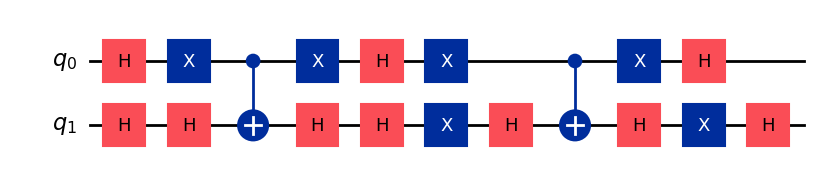

Statevector: [ 0.+0.j  0.+0.j -1.+0.j  0.+0.j]
10 amplitud= (-1+0j) probabilidad= 1.0 fase (rad)= 3.1416


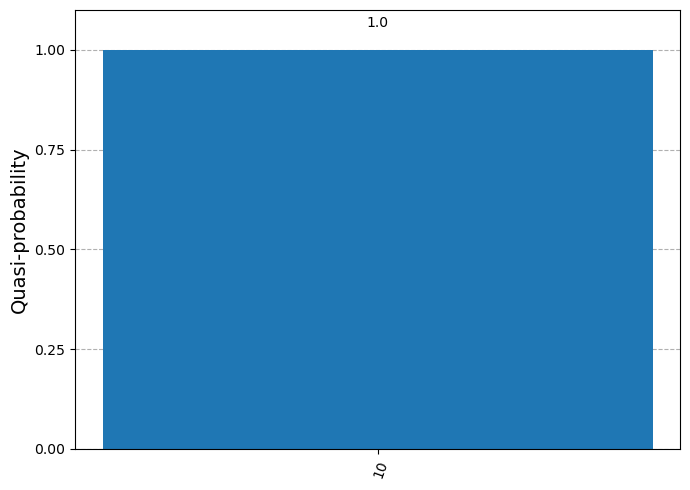

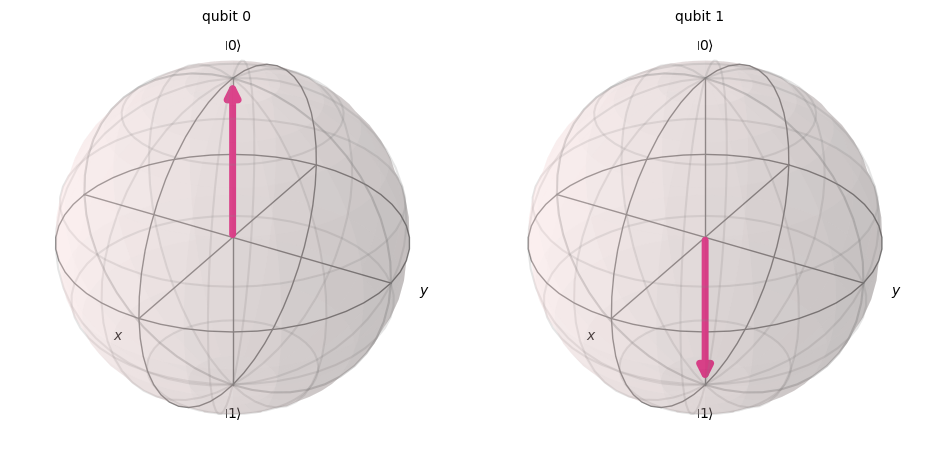

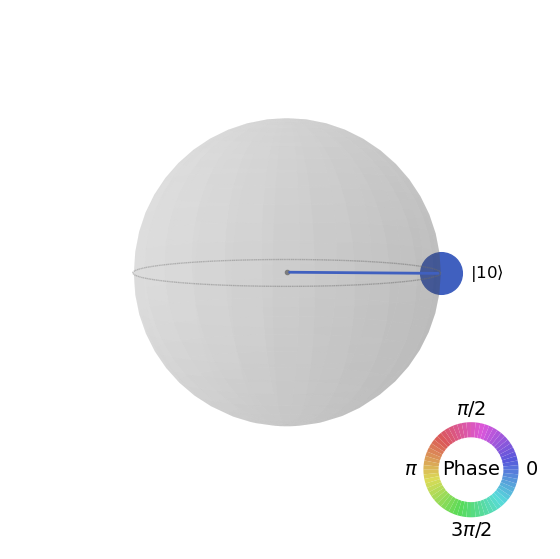

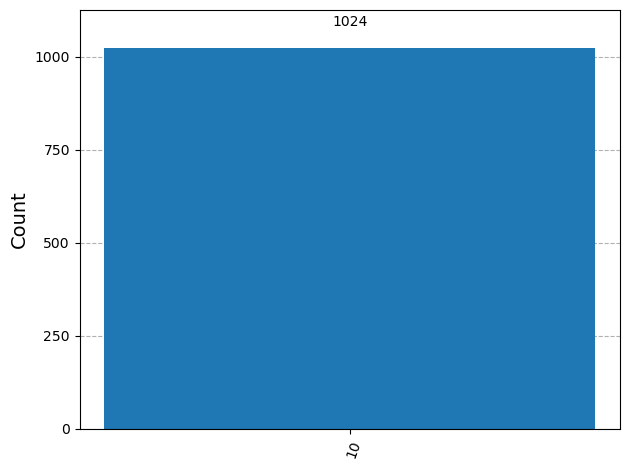

{'10': 1024}

In [59]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
def marcar(q, bitstring, wires):
    ceros=[w for w,b in zip(wires,reversed(bitstring)) if b=='0']
    for w in ceros: q.x(w)
    q.h(wires[-1]); q.mcx(wires[:-1],wires[-1]); q.h(wires[-1])
    for w in ceros: q.x(w)
def difusor(q,wires):
    q.h(wires); q.x(wires)
    q.h(wires[-1]); q.mcx(wires[:-1],wires[-1]); q.h(wires[-1])
    q.x(wires); q.h(wires)
grover=QuantumCircuit(2); grover.h([0,1]); marcar(grover,'10',[0,1]); difusor(grover,[0,1])
analizar(grover); medir(grover)

## 9. De problema clásico a circuito
Tres fábricas A, B, C. Al menos dos abiertas; A y C incompatibles; A o B abierta. Se codifican A=q0, B=q1, C=q2. Soluciones en orden CBA: 011 y 110. El oráculo usa compute–mark–uncompute con un auxiliar. El coste se compara después clásicamente; no se demuestra ventaja cuántica.

#### Traducir restricciones a un oráculo

**Qué vamos a hacer y por qué.** Cada variable binaria indica si una fábrica está abierta. Primero enumeramos las combinaciones para verificar las restricciones; después construimos un circuito que marca las válidas usando un auxiliar. Compute–mark–uncompute restaura el auxiliar para evitar entrelazamiento residual.

**Qué debes observar al ejecutar la celda.** Las soluciones válidas son 011 y 110 en orden CBA. El ejemplo construye el oráculo a partir de una enumeración clásica: es didáctico, no un método escalable ni una demostración de ventaja.

Soluciones clásicas: ['011', '110']


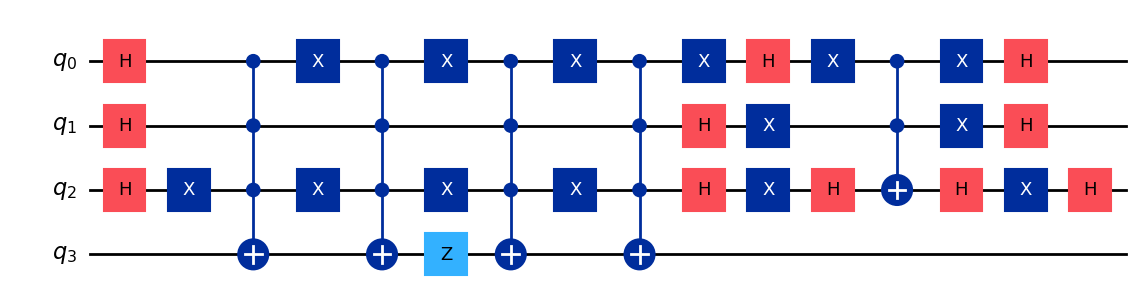

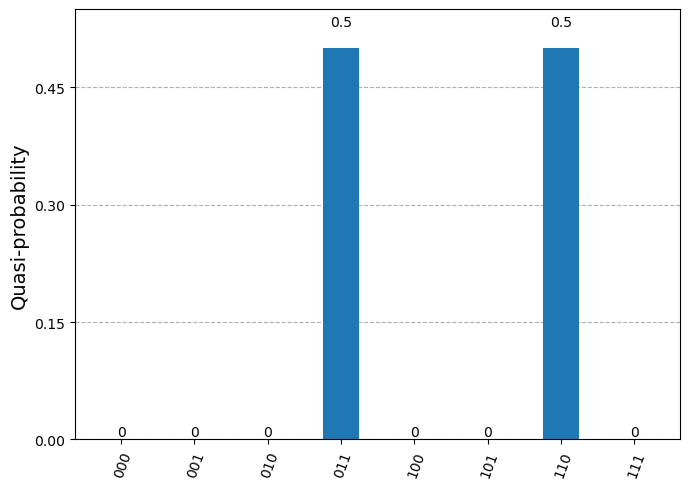

Costes: A+B = 105000 EUR; B+C = 120000 EUR. Mejor solución: A+B.


In [62]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
def valida(a,b,c): return a+b+c>=2 and not(a and c) and (a or b)
validas=[format(i,'03b') for i in range(8) if valida(i&1,(i>>1)&1,(i>>2)&1)]
print('Soluciones clásicas:',validas)
# Construcción didáctica por tabla de verdad (no escalable)
def compute(q):
    for bits in validas:
        zeros=[i for i,b in enumerate(reversed(bits)) if b=='0']
        for i in zeros: q.x(i)
        q.mcx([0,1,2],3)
        for i in zeros: q.x(i)
q=QuantumCircuit(4); q.h([0,1,2]); compute(q); q.z(3); compute(q); difusor(q,[0,1,2])
display(q.draw('mpl')); sv=Statevector.from_instruction(q)
probs=sv.probabilities_dict(qargs=[0,1,2]); display(plot_distribution(probs))
assert np.isclose(sum(probs[k] for k in validas),1)
print('Costes: A+B = 105000 EUR; B+C = 120000 EUR. Mejor solución: A+B.')

## 10. Teleportación cuántica
Se prepara un estado arbitrario en q0, un par de Bell en q1/q2 y se realizan dos mediciones. Las correcciones X y Z sobre q2 dependen de los bits clásicos. Verificamos mediante la inversa de la preparación: q2 debe medirse como 0. No se transmite información más rápido que la luz.

#### Teleportar un estado

**Qué vamos a hacer y por qué.** Se prepara un estado en q0 mediante RY y RZ. q1 y q2 comparten un par entrelazado. La medición conjunta de q0 y q1 produce dos bits clásicos que determinan las correcciones X y Z sobre q2. if_test expresa estas condiciones.

**Qué debes observar al ejecutar la celda.** La inversa de la preparación transforma el estado recuperado en |0⟩. El bit c2 debe ser cero en la simulación ideal. El estado original se destruye en el proceso y no se transmite información sin comunicación clásica.

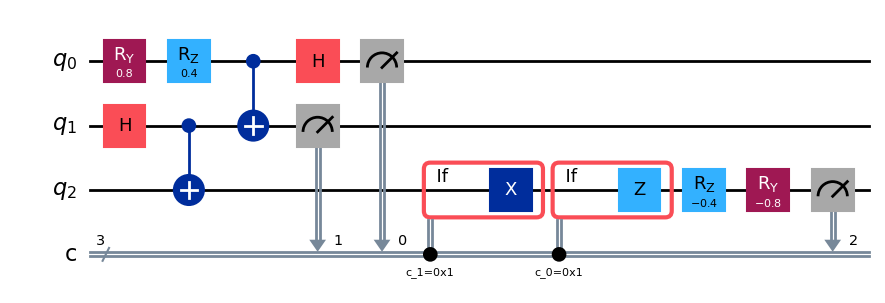

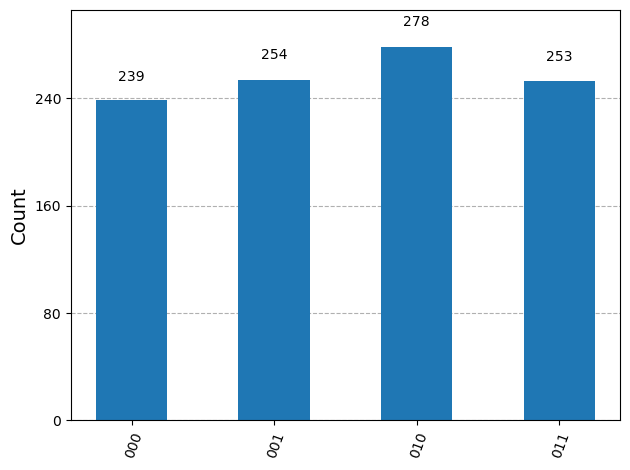

Probabilidad de verificación correcta: 1.0


In [65]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
qr=QuantumRegister(3,'q'); cr=ClassicalRegister(3,'c')
tele=QuantumCircuit(qr,cr)
theta,phi=0.8,0.4
tele.ry(theta,0); tele.rz(phi,0)
tele.h(1); tele.cx(1,2); tele.cx(0,1); tele.h(0)
tele.measure(0,0); tele.measure(1,1)
with tele.if_test((cr[1],1)): tele.x(2)
with tele.if_test((cr[0],1)): tele.z(2)
tele.rz(-phi,2); tele.ry(-theta,2); tele.measure(2,2)
display(tele.draw('mpl')); counts=medir(tele)
print('Probabilidad de verificación correcta:',sum(v for k,v in counts.items() if k[0]=='0')/SHOTS)

## 11. Simulación con ruido
Modelo ilustrativo de error despolarizante; no representa un procesador concreto. Comparar el soporte y la frecuencia de los resultados con la simulación ideal.

#### Simulación ideal frente a ruido

**Qué vamos a hacer y por qué.** NoiseModel asigna errores a operaciones concretas. El modelo despolarizante mezcla el estado con componentes aleatorias; la tasa elegida es ilustrativa. AerSimulator permite repetir el mismo circuito bajo ambos modelos.

**Qué debes observar al ejecutar la celda.** En el circuito Bell ideal solo aparecen 00 y 11. Con ruido pueden aparecer 01 y 10. Un histograma no identifica por sí solo el mecanismo de error.

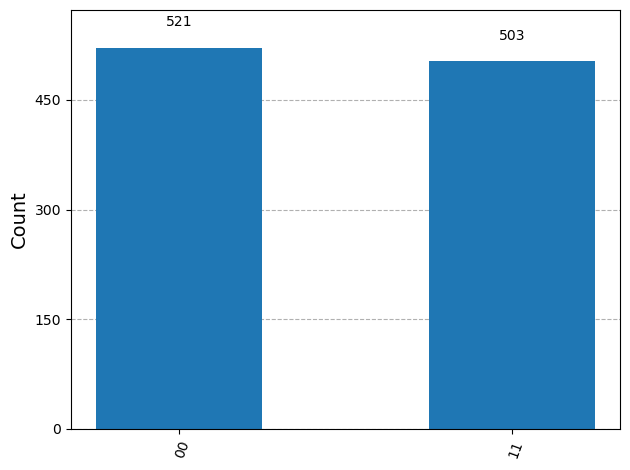

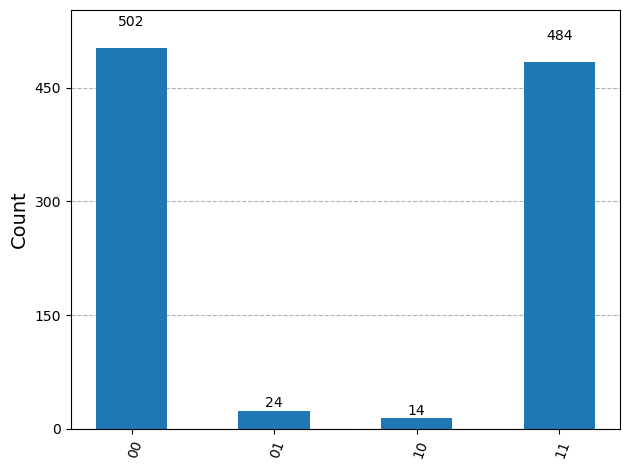

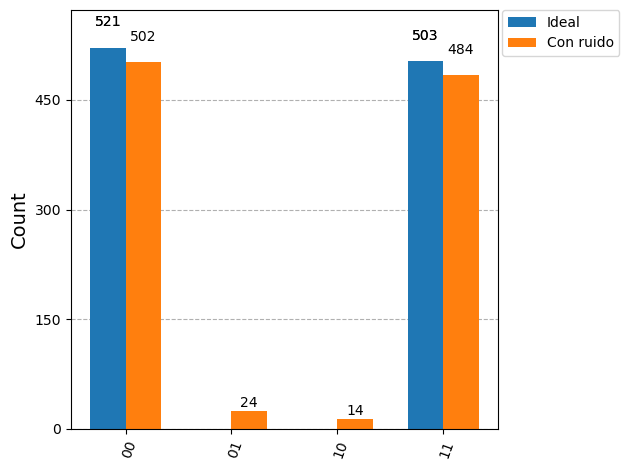

In [68]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
from qiskit_aer.noise import NoiseModel, depolarizing_error
noise=NoiseModel(); noise.add_all_qubit_quantum_error(depolarizing_error(0.08,2),['cx'])
noisy=AerSimulator(noise_model=noise)
ideal=medir(bell); ruidoso=medir(bell,backend=noisy)
display(plot_histogram([ideal,ruidoso],legend=['Ideal','Con ruido']))

## 12. IBM Quantum: hardware real (opcional)
Requiere cuenta, instancia y credenciales configuradas según la documentación oficial. Nunca publicar tokens en GitHub. La ejecución consume cuota. La celda queda desactivada por defecto. Comparar número de qubits, profundidad, conectividad, tiempos T1/T2 y errores de puertas/lectura en el portal. Para teleportación seleccionar hardware compatible con circuitos dinámicos.

#### Ejecutar en una QPU

**Qué vamos a hacer y por qué.** QiskitRuntimeService conecta con una cuenta configurada. least_busy selecciona un backend disponible con los filtros indicados; no garantiza que sea el más preciso. El pass manager transpila a instrucciones admitidas y SamplerV2 recoge muestras de medida.

**Qué debes observar al ejecutar la celda.** No actives RUN_QPU sin autorización y credenciales. Consulta cuota y condiciones de acceso. El hardware puede devolver resultados distintos del ideal por ruido, calibración y transpilación.

In [71]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
RUN_QPU=False
if RUN_QPU:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
    from qiskit.transpiler import generate_preset_pass_manager
    service=QiskitRuntimeService()
    backend=service.least_busy(operational=True,simulator=False,min_num_qubits=2)
    print('Backend:',backend.name,'Qubits:',backend.num_qubits)
    circuito=bell.copy(); circuito.measure_all()
    pm=generate_preset_pass_manager(backend=backend,optimization_level=1)
    isa=pm.run(circuito)
    print('Profundidad lógica/física:',circuito.depth(),isa.depth())
    sampler=SamplerV2(mode=backend)
    job=sampler.run([isa],shots=SHOTS)
    print('Job ID:',job.job_id())
    real=job.result()[0].data.meas.get_counts()
    display(plot_histogram([ideal,real],legend=['Ideal','QPU']))

### 12.1. Características de un procesador cuántico
No basta comparar el número de qubits. La calidad, conectividad y adecuación al circuito son decisivas.

| Métrica | Interpretación |
|---|---|
| Qubits físicos y lógicos | Los físicos son dispositivos; un qubit lógico protegido puede requerir muchos físicos. |
| Topología / coupling map | Pares de qubits que admiten operaciones directas; el routing puede introducir puertas adicionales. |
| T1 (µs) | Tiempo característico de relajación energética. Mayor suele ser mejor. |
| T2 (µs) | Tiempo característico de pérdida de coherencia de fase. Mayor suele ser mejor. |
| Error de puertas 1Q y 2Q | Estimación calibrada del error de operación; menor suele ser mejor. |
| Readout error | Error asociado a lectura; menor suele ser mejor. |
| Duración de puertas y lectura | Tiempo por operación, relevante frente a la decoherencia. |
| Puertas nativas / ISA | Instrucciones que el backend puede ejecutar directamente. |
| Frecuencia | Frecuencia de transición del qubit, en GHz. No es velocidad de ejecución. |
| Estado y cola | Disponibilidad operativa y trabajos pendientes; no miden fidelidad. |
| CLOPS / Quantum Volume | Indicadores de rendimiento y capacidad en protocolos específicos, si se publican; no sustituyen las métricas del circuito concreto. |

Las métricas cambian con las calibraciones. Los errores ausentes no equivalen a cero. Referencia: [IBM Quantum: detalles del backend](https://quantum.cloud.ibm.com/docs/en/ibm-quantum-compute/qpu-information).

### 12.2. Inspección local de un backend simulado
Usamos GenericBackendV2 con valores sintéticos reproducibles para aprender sin cuenta IBM. No son calibraciones de una QPU real.

#### Consultar el backend

**Qué vamos a hacer y por qué.** GenericBackendV2 construye un dispositivo ficticio con conectividad y parámetros sintéticos. target contiene instrucciones admitidas y propiedades por conjunto de qubits. Los tiempos suelen expresarse en segundos y las frecuencias en Hz; el código puede convertirlos a unidades prácticas.

**Qué debes observar al ejecutar la celda.** Compara T1 y T2, errores de lectura y de puertas, y aristas de conectividad. No interpretes estos valores como datos de una máquina IBM real.

In [75]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.visualization import plot_coupling_map
from qiskit.transpiler import generate_preset_pass_manager
backend_demo = GenericBackendV2(num_qubits=5, coupling_map=[[0,1],[1,0],[1,2],[2,1],[2,3],[3,2],[3,4],[4,3]], seed=42)

def inspeccionar_backend(b, limite=5):
    print('Backend:', b.name, '| Qubits:', b.num_qubits)
    print('Operaciones:', b.operation_names)
    print('Conexiones:', list(b.coupling_map.get_edges())[:20] if b.coupling_map else 'No especificadas')
    def escala(x, factor): return 'N/D' if x is None else round(x*factor, 3)
    for i in range(min(b.num_qubits, limite)):
        p = b.qubit_properties(i)
        print('q', i, 'T1 (µs):', escala(p.t1,1e6), 'T2 (µs):', escala(p.t2,1e6), 'frecuencia (GHz):', escala(p.frequency,1e-9))
        for op in ['x','sx','measure']:
            if op in b.target and (i,) in b.target[op]:
                ip = b.target[op][(i,)]
                if ip is not None: print(' ',op,'error (%):',escala(ip.error,100),'duración (ns):',escala(ip.duration,1e9))
    for op in ['cx','cz','ecr']:
        if op in b.target:
            for pair, ip in list(b.target[op].items())[:limite]:
                if ip is not None: print(op, pair, 'error (%):',escala(ip.error,100),'duración (ns):',escala(ip.duration,1e9))

inspeccionar_backend(backend_demo)
display(plot_coupling_map(5, [[0,i] for i in range(5)], list(backend_demo.coupling_map.get_edges())))


Backend: generic_backend_5q | Qubits: 5
Operaciones: ['cx', 'id', 'rz', 'sx', 'x', 'reset', 'delay', 'measure']
Conexiones: [(0, 1), (1, 0), (1, 2), (2, 1), (2, 3), (3, 2), (3, 4), (4, 3)]
q 0 T1 (µs): 177.396 T2 (µs): 143.888 frecuencia (GHz): 5.429
  x error (%): 0.01 duración (ns): 30.192
  sx error (%): 0.01 duración (ns): 54.834
  measure error (%): 0.283 duración (ns): 1076.922
q 1 T1 (µs): 169.737 T2 (µs): 109.418 frecuencia (GHz): 5.488
  x error (%): 0.01 duración (ns): 49.95
  sx error (%): 0.01 duración (ns): 39.294
  measure error (%): 0.318 duración (ns): 1312.02
q 2 T1 (µs): 176.114 T2 (µs): 178.606 frecuencia (GHz): 5.064
  x error (%): 0.009 duración (ns): 53.28
  sx error (%): 0.009 duración (ns): 54.168
  measure error (%): 0.28 duración (ns): 1142.856
q 3 T1 (µs): 145.039 T2 (µs): 137.08 frecuencia (GHz): 5.463
  x error (%): 0.009 duración (ns): 47.064
  sx error (%): 0.01 duración (ns): 38.628
  measure error (%): 0.016 duración (ns): 943.056
q 4 T1 (µs): 164.387 T

MissingOptionalLibraryError: "The 'Graphviz' library is required to use 'plot_coupling_map'.  To install, follow the instructions at https://graphviz.org/download/. Qiskit needs the Graphviz binaries, which the 'graphviz' package on pip does not install. You must install the actual Graphviz software."

### 12.3. Transpilación: circuito lógico frente a físico
La transpilación traduce las puertas al conjunto nativo, asigna qubits físicos y resuelve restricciones de conectividad. Compara profundidad, número de operaciones y layout. El backend sintético permite experimentar sin consumir tiempo de QPU.

#### Del circuito lógico al físico

**Qué vamos a hacer y por qué.** El layout asigna qubits virtuales a físicos. Si dos qubits no están conectados, el compilador puede introducir operaciones de routing o modificar la asignación. La optimización puede cancelar puertas o traducirlas a la base nativa.

**Qué debes observar al ejecutar la celda.** Compara depth y count_ops antes y después. Un circuito físicamente más costoso puede acumular más errores. Cambia el layout y el nivel de optimización y observa el efecto.

In [ ]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
logico = QuantumCircuit(3)
logico.h(0); logico.cx(0,2); logico.measure_all()
pm_demo = generate_preset_pass_manager(backend=backend_demo, optimization_level=1, seed_transpiler=42, initial_layout=[0,1,4])
fisico = pm_demo.run(logico)
for nombre, circ in [('Lógico',logico),('Transpilado',fisico)]:
    print(nombre, 'profundidad:',circ.depth(), 'operaciones:',circ.count_ops())
    display(circ.draw('mpl', idle_wires=False))
print('Layout:',fisico.layout)


### 12.4. Consultar procesadores IBM disponibles (opcional, sin enviar trabajos)
Requiere credenciales configuradas de forma segura. Consulta los backends accesibles a tu cuenta, compara métricas y revisa la fecha de calibración. [Documentación IBM](https://quantum.cloud.ibm.com/docs/en/ibm-quantum-compute/qpu-information).

#### Elegir un procesador real

**Qué vamos a hacer y por qué.** La consulta lista dispositivos operativos accesibles para la cuenta. Las colas y calibraciones cambian. Conviene elegir según conectividad, errores, profundidad transpilada y requisitos de circuitos dinámicos, no solo número de qubits.

**Qué debes observar al ejecutar la celda.** CONSULTAR_IBM permanece desactivado. Consultar metadatos no envía un trabajo cuántico; nunca incluyas tokens en archivos del repositorio.

In [ ]:
# Ejecuta esta celda y contrasta el resultado con la explicación anterior.
CONSULTAR_IBM = False
if CONSULTAR_IBM:
    from qiskit_ibm_runtime import QiskitRuntimeService
    servicio = QiskitRuntimeService()
    for b in servicio.backends(simulator=False, operational=True):
        print(b.name, b.num_qubits, b.status().pending_jobs)
    elegido = servicio.least_busy(simulator=False, operational=True, min_num_qubits=2)
    inspeccionar_backend(elegido)
    props = elegido.properties()
    if props is not None: print('Última actualización:', props.last_update_date)


## 13. Ecosistema y documentación
- [IBM Quantum Composer](https://quantum.ibm.com/composer)
- [IBM Quantum Learning](https://learning.quantum.ibm.com/)
- [Qiskit: Sampler](https://quantum.cloud.ibm.com/docs/en/ibm-quantum-compute/get-started-with-sampler)
- [Circuitos dinámicos](https://qiskit.qotlabs.org/docs/guides/execute-dynamic-circuits)
- [IBM Quantum roadmap](https://www.ibm.com/roadmaps/quantum/)
- [Qiskit Aer](https://qiskit.github.io/qiskit-aer/), [PennyLane](https://pennylane.ai/), [Cirq](https://quantumai.google/cirq), [Qiskit Algorithms](https://qiskit-community.github.io/qiskit-algorithms/), [Qiskit Optimization](https://qiskit-community.github.io/qiskit-optimization/)

## 14. Ejercicios propuestos
1. Preparar $|-\rangle$ de dos formas y comprobar equivalencia salvo fase global.
2. Comparar HZH con X mediante sus matrices.
3. Crear los cuatro estados de Bell y distinguirlos en una base adecuada.
4. Cambiar los shots a 100, 1024 y 10000: comparar fluctuaciones.
5. Preparar el sumador con entradas en superposición y analizar el estado conjunto.
6. Cambiar la solución de Grover a 01 y probar dos iteraciones.
7. Modificar las restricciones de las fábricas y recalcular el número de iteraciones de Grover.
8. Cambiar theta y phi en teleportación, y eliminar una corrección para observar el efecto.
9. Comparar el circuito Bell ideal, con ruido y en hardware; justificar diferencias sin atribuirlas exclusivamente a un único error.

**Conclusión:** distinguir amplitudes, probabilidades, fases, muestreo y ruido; una demostración pequeña no prueba ventaja cuántica.

## 14. Autoevaluación y soluciones orientativas

1. ¿Por qué H y HZ tienen el mismo histograma? Porque solo cambia la fase relativa, no el módulo de las amplitudes.
2. ¿Por qué una esfera de Bloch local de Bell tiene vector nulo? Porque el estado reducido es I/2.
3. ¿Cómo distinguir los cuatro estados de Bell? Mediante el analizador CX–H; medir únicamente en Z no distingue los signos.
4. ¿Qué diferencia hay entre compose y append? El primero inserta operaciones; el segundo añade una instrucción, que puede encapsular un circuito.
5. ¿Por qué transpilar? Para adaptar el circuito a instrucciones y conectividad físicas.
6. ¿Qué diferencia hay entre amplitud y frecuencia? La amplitud es compleja; su módulo al cuadrado es una probabilidad y la frecuencia es una estimación experimental.
7. ¿Por qué no basta observar ruido para saber su origen? Distintos mecanismos pueden generar distribuciones similares.

**Práctica final:** crea un circuito Bell, cambia su fase, visualiza el estado, predice las medidas en X y Z y compara simulación ideal con ruido. Justifica cada decisión en una celda Markdown.